# ENGG 680 — Skin Lesion Classification with ResNet-18

**Project notebook | Data preparation, model development, calibration, and independent test evaluation**

This notebook documents the completed HAM10000 workflow. It retains meaningful experimental decisions (duplicate-image checks, lesion-level splitting, the initial model, fine-tuning, augmentation, and threshold comparisons) while removing repeated session-recovery checks. Some training stages were performed across separate Colab sessions and depend on checkpoints saved in Google Drive. **Existing outputs are retained as a record; the notebook has been syntax-checked but not re-executed end to end. Running from a fresh session requires the original image folders, metadata, and saved model checkpoints in the specified Google Drive paths.**

**Label convention:** benign = 0; malignant = 1. The 80% threshold is a *referral decision threshold*, not the 95% statistical confidence interval.


In [1]:
# Import Python libraries
import pandas as pd
  # organizes and analyses the metadata
import numpy as np
  # performs numerical operations
import matplotlib.pyplot as plt
  # creates graphs to visualize the dataset
import os
  # accesses folders and files

In [2]:
# Connect Google Drive
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
# Locate your files
# Path to the dataset folder
folder_path = "/content/drive/MyDrive/ENGG680"

# List all files in the folder
os.listdir(folder_path)

['HAM10000_metadata.csv',
 'HAM10000_images_part_1',
 'HAM10000_images_part_2',
 'HAM10000_images',
 'HAM10000_Splits',
 'resnet18_best_initial.pt',
 'resnet18_best_finetuned.pt',
 'resnet18_finetune_recovery.pt',
 'resnet18_calibration_settings.json',
 'Final_Test_Results',
 'Model_Optimization',
 'Threshold_Optimization',
 'Additional_Finetuning',
 'Experiment3_Error_Analysis',
 'Final_Report_Figures',
 'Pythons',
 'resnet18_best_augmented.pt',
 'resnet18_augmented_recovery.pt',
 'resnet18_augmented_calibration_settings.json',
 'resnet18_augmented_referral_analysis.csv',
 'ENGG 680 Final Model.ipynb']

In [ ]:
# Load the metadata
metadata_path = os.path.join(folder_path, "HAM10000_metadata.csv")

metadata = pd.read_csv(metadata_path)

# Display the first 5 rows
metadata.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


In [ ]:
# Identify the seven skin lesion categories
# Count the number of images for each diagnosis
metadata["dx"].value_counts()

# mel - melanoma
# bcc - basal cell carcinoma
# akiec - actinic keratoses and intraepithelial carcinoma
# bkl - benign keratosis-like lesions
# nv - melanocytic nevi
# df - dermatofibroma
# vasc - vascular lesions

,count
dx,
nv,6705
mel,1113
bkl,1099
bcc,514
akiec,327
vasc,142
df,115


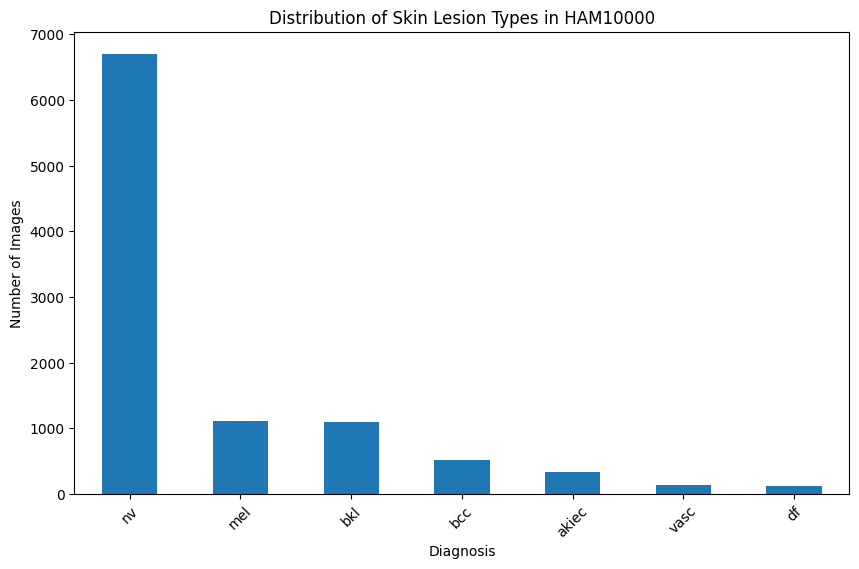

In [ ]:
# Visualize the distribution of lesion types

# Count images in each diagnosis category
diagnosis_counts = metadata["dx"].value_counts()

# Create a bar graph
plt.figure(figsize=(10,6))

diagnosis_counts.plot(kind="bar")

plt.title("Distribution of Skin Lesion Types in HAM10000")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.show()

In [ ]:
# Create the table using Pandas
# Count the number of images for each diagnosis
diagnosis_counts = metadata["dx"].value_counts()

# Create a table
diagnosis_table = pd.DataFrame({
    "Diagnosis": diagnosis_counts.index,
    "Number of Images": diagnosis_counts.values
})

# Calculate percentage of total images
diagnosis_table["Percentage (%)"] = (
    diagnosis_table["Number of Images"] / len(metadata) * 100
).round(2)

# Define the full diagnosis names
diagnosis_names = {
    "nv": "Melanocytic Nevi",
    "mel": "Melanoma",
    "bkl": "Benign Keratosis",
    "bcc": "Basal Cell Carcinoma",
    "akiec": "Actinic Keratoses / Intraepithelial Carcinoma",
    "vasc": "Vascular Lesions",
    "df": "Dermatofibroma"
}

# Replace abbreviations with full names
diagnosis_table["Diagnosis"] = (
    diagnosis_table["Diagnosis"].map(diagnosis_names)
)

# Display the table
diagnosis_table

,Diagnosis,Number of Images,Percentage (%)
0,Melanocytic Nevi,6705,66.95
1,Melanoma,1113,11.11
2,Benign Keratosis,1099,10.97
3,Basal Cell Carcinoma,514,5.13
4,Actinic Keratoses / Intraepithelial Carcinoma,327,3.27
5,Vascular Lesions,142,1.42
6,Dermatofibroma,115,1.15


In [ ]:
# Checking for missing data and duplicates
# Check the size of the dataset
print("Dataset shape:", metadata.shape)
      # returns the number of rows and columns

# Check for missing values in each column
print("\nMissing values:")
print(metadata.isnull().sum())
      # counts missing valyes in each column

# Check for duplicate image IDs
print("\nDuplicate image IDs:")
print(metadata["image_id"].duplicated().sum())
      # checks whether an image ID appears more than once

# Check how many unique lesions exist
print("\nUnique lesions:")
print(metadata["lesion_id"].nunique())
      # counts the number of unique lesions
      # ** VERY IMPORTANT!!!

Dataset shape: (10015, 8)

Missing values:
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dataset          0
dtype: int64

Duplicate image IDs:
0

Unique lesions:
7470


In [ ]:
# Create a summary table of missing values
missing_table = pd.DataFrame({
    "Variable": metadata.columns,
    "Missing Values": metadata.isnull().sum().values,
    "Percentage Missing (%)": (
        metadata.isnull().sum().values / len(metadata) * 100
    ).round(2)
})

# Display the formatted table
missing_table.style.format({
    "Percentage Missing (%)": "{:.2f}%"
}).set_caption(
    "Table 2. Missing Values in HAM10000 Metadata"
)

,Variable,Missing Values,Percentage Missing (%)
0,lesion_id,0,0.00%
1,image_id,0,0.00%
2,dx,0,0.00%
3,dx_type,0,0.00%
4,age,57,0.57%
5,sex,0,0.00%
6,localization,0,0.00%
7,dataset,0,0.00%


In [ ]:
# Define benign and malignant categories

# Melanoma (mel) -> malignant
# Basal cell carcinoma (bcc) -> malignant
# Melanocytic nevi (nv) -> benign
# Benign keratosis (bkl) -> benign
# Dermatofibroma (df) -> benign
# Vascular lesions (vasc) -> benign
# Actinic keratoses / intraepithelial carcinoma (akiec) -> exclude, initially.
    # this contains both premalignant and in-situ lesions


# this would leave:
  # 8,061 Benign images (83.21%)
  # 1,627 Malignant images (16.79%)

In [ ]:
# This code creates a separate DataFrame called metadata_binary, preserving the original metadata DataFrame
# Then, it assigns the classifications


# Create a dictionary for binary classification
classification_map = {
    "mel": "Malignant",
    "bcc": "Malignant",
    "nv": "Benign",
    "bkl": "Benign",
    "df": "Benign",
    "vasc": "Benign"
}
        # assigns each diagnosis to either benign or malignant

# Creates a copy of the original metadata
metadata_binary = metadata.copy()
        # preserves your original metadata

# Assign benign or malignant labels
metadata_binary["classification"] = (
    metadata_binary["dx"].map(classification_map)
)
        # creates a new classification column

# Exclude categories without a binary label
metadata_binary = metadata_binary.dropna(
    subset=["classification"]
).copy()
        # removes rows without an assigned classification, which should only be the akiec category

In [ ]:
# Count images in each binary classification
binary_counts = metadata_binary["classification"].value_counts()

# Create a summary table
binary_table = pd.DataFrame({
    "Classification": binary_counts.index,
    "Number of Images": binary_counts.values
})

# Calculate percentages
binary_table["Percentage (%)"] = (
    binary_table["Number of Images"]
    / len(metadata_binary) * 100
).round(2)

# Display formatted table
binary_table.style.format({
    "Number of Images": "{:,}",
    "Percentage (%)": "{:.2f}%"
}).set_caption(
    "Table 3. Distribution of Benign and Malignant Skin Lesions"
)

,Classification,Number of Images,Percentage (%)
0,Benign,"8,061",83.21%
1,Malignant,"1,627",16.79%


## 2. Image integrity and metadata matching

The downloaded folders contained eight extra files with a ` (1)` filename suffix. We checked that each corresponded to an image already listed in the metadata and excluded the extra copies from matching.


# 2. Load and sort the JPEG Images

In [ ]:
# Check the image ZIP files
# List the files stored in the ENGG680 folder
import os

folder_path = "/content/drive/MyDrive/ENGG680"

# Display the exact filenames
for file in os.listdir(folder_path):
  print(repr(file))

'HAM10000_metadata.csv'
'HAM10000_images_part_1'
'HAM10000_images_part_2'
'HAM10000_images'
'HAM10000_Splits'
'resnet18_best_initial.pt'
'resnet18_best_finetuned.pt'
'resnet18_finetune_recovery.pt'
'resnet18_calibration_settings.json'
'Final_Test_Results'
'Model_Optimization'
'Threshold_Optimization'
'Additional_Finetuning'
'Experiment3_Error_Analysis'
'Final_Report_Figures'
'Pythons'
'resnet18_best_augmented.pt'
'resnet18_augmented_recovery.pt'
'resnet18_augmented_calibration_settings.json'
'resnet18_augmented_referral_analysis.csv'
'ENGG 680 Final Model.ipynb'


In [ ]:
# Check whether Part 1 and Part 2 are folders
for part in [1, 2]:

  path = os.path.join(
      folder_path,
      f"HAM10000_images_part_{part}"
  )

  print(f"Part {part}:")
  print("Is a folder:", os.path.isdir(path))
  print("Is a file:", os.path.isfile(path))
  print()

Part 1:
Is a folder: True
Is a file: False

Part 2:
Is a folder: True
Is a file: False



In [ ]:
# Count the images in both folders

# Define the two image folders
image_folders = [
    os.path.join(folder_path, "HAM10000_images_part_1"),
    os.path.join(folder_path, "HAM10000_images_part_2")
]

# Create an empty list to store image paths
image_paths = []

# Search both folders for JPEG images
for folder in image_folders:
  for root, dirs, files in os.walk(folder):
    for file in files:
      if file.lower().endswith((".jpg", ".jpeg")):
        image_paths.append(os.path.join(root, file))

# Dislay the total number of images
print("Total images found:", len(image_paths))

Total images found: 10023


**Image integrity finding:** Eight extra filenames were detected; investigate whether these are duplicated downloads.


In [ ]:
# Check for duplicate image filenames

# Extract image IDs from the filenames
image_ids = [
    os.path.splitext(os.path.basename(path))[0]
    for path in image_paths
]

# Count duplicate image IDs
image_counts = pd.Series(image_ids).value_counts()

# Display duplicate image IDs
duplicate_images = image_counts[image_counts > 1]

print("Duplicate image IDs:", len(duplicate_images))
print("Extra file copies:", (duplicate_images - 1).sum())

# Display duplicated images
print(duplicate_images)

Duplicate image IDs: 0
Extra file copies: 0
Series([], Name: count, dtype: int64)


In [ ]:
# Identify the eight additional images

# Get image IDs from the original metadata
metadata_ids = set(metadata["image_id"])

# Get image IDs from the image folders
folder_ids = set(image_ids)

# Identify images not included in the metadata
extra_images = folder_ids - metadata_ids

# Identify metadata records without matching images
missing_images = metadata_ids - folder_ids

# Display the results
print("Unique image IDs found:", len(folder_ids))
print("Images not in metadata:", len(extra_images))
print("Metadata images not found:", len(missing_images))

print("\nExtra image IDs:")
print(sorted(extra_images))

print("\nMissing image IDs:")
print(sorted(missing_images))

Unique image IDs found: 10023
Images not in metadata: 8
Metadata images not found: 0

Extra image IDs:
['ISIC_0024583 (1)', 'ISIC_0024597 (1)', 'ISIC_0025689 (1)', 'ISIC_0025845 (1)', 'ISIC_0026394 (1)', 'ISIC_0027049 (1)', 'ISIC_0028385 (1)', 'ISIC_0029064 (1)']

Missing image IDs:
[]


The eight extra files had a ` (1)` suffix, suggesting duplicate downloads rather than additional metadata records. The next check verifies the corresponding original IDs.


In [ ]:
# Verify that the original image IDs exist in your metadata

# Remove the " (1)" suffix from extra image IDs
original_ids = [
    image_id.replace(" (1)", "")
    for image_id in extra_images
]

# Check whether the original IDs exist in the metadata
for image_id in original_ids:
    print(image_id, image_id in metadata_ids)

ISIC_0026394 True
ISIC_0029064 True
ISIC_0025689 True
ISIC_0024583 True
ISIC_0025845 True
ISIC_0028385 True
ISIC_0024597 True
ISIC_0027049 True


All eight original image IDs were present in the metadata, so the duplicate copies were excluded from the image-to-metadata mapping.


# Matching the images to the benign and malignant classifications

In [ ]:
# Back to matching the images to the benign and malignant classifications

# Create a dictionary matching image IDs to file paths
image_path_map = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_paths
    if os.path.splitext(os.path.basename(path))[0] in metadata_ids
}

# Match image paths to the binary classification dataset
metadata_binary["image_path"] = (
    metadata_binary["image_id"].map(image_path_map)
)

# Check for missing image paths
print("Images without matching files:",
      metadata_binary["image_path"].isnull().sum())

# Display the first five rows
metadata_binary[
    ["image_id", "dx", "classification", "image_path"]
].head()

Images without matching files: 0


,image_id,dx,classification,image_path
0,ISIC_0027419,bkl,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
1,ISIC_0025030,bkl,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
2,ISIC_0026769,bkl,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
3,ISIC_0025661,bkl,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
4,ISIC_0031633,bkl,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...


## 3. Lesion-level training, validation, and test split

The split is performed by **lesion ID**, not individual image, to avoid placing images of the same lesion in different datasets. This was a key data-leakage safeguard.


**Split plan:** approximately 70% training, 15% validation, and 15% test, assigned at the lesion level to prevent leakage.
1. Training set (70%) - used to train the CNN
2. Validation set (15%) - used to tune the model and monitor its performance
3. Testing set (15%) - used to evaluate your final model on unseen data


In [ ]:
# Spliting the images into training, validaiton, and testing sets

from sklearn.model_selection import train_test_split

# Check that all images have matching file paths
assert metadata_binary["image_path"].notna().all()

#Verify each lesion has only one classification
assert(
    metadata_binary.groupby("lesion_id")["classification"]
    .nunique().max() == 1
)

# Create a table containing each unique lesions and its classification
unique_lesions = metadata_binary[
    ["lesion_id", "classification"]
  ].drop_duplicates()

# Split lesions into 70% training and 30% remaining
train_lesions, remaining_lesions = train_test_split(
    unique_lesions,
    test_size=0.30,
    random_state=42,
    stratify=unique_lesions["classification"]
)

#Split remaining lesions into 15% validation and 15% testing
val_lesions, test_lesions = train_test_split(
    remaining_lesions,
    test_size=0.50,
    random_state=42,
    stratify=remaining_lesions["classification"]
)

# Match all images to their assigned lesion groups
train_df = metadata_binary[
    metadata_binary["lesion_id"].isin(train_lesions["lesion_id"])
].copy()

val_df = metadata_binary[
    metadata_binary["lesion_id"].isin(val_lesions["lesion_id"])
].copy()

test_df = metadata_binary[
    metadata_binary["lesion_id"].isin(test_lesions["lesion_id"])
].copy()

# Display the number of images in each dataset
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("Total images:",
      len(train_df) + len(val_df) + len(test_df))

Training images: 6813
Validation images: 1460
Testing images: 1415
Total images: 9688


In [ ]:
# Count benign and malignant distribution

# Count the number of benign and malignant images in each dataset
distribution = pd.DataFrame({
    "Training": train_df["classification"].value_counts(),
    "Validation": val_df["classification"].value_counts(),
    "Testing": test_df["classification"].value_counts()
}).fillna(0).astype(int)

# Display the results
print("Number of images in each classification:")
display(distribution)

Number of images in each classification:


,Training,Validation,Testing
classification,,,
Benign,5673,1209,1179
Malignant,1140,251,236


In [ ]:
# Calculate the percentage of benign and malignant image in each dataset
distribution_percent = distribution.div(
    distribution.sum(axis=0), axis=1
) * 100

# Display percentages rounded to two decimal places
print("Percentage distribution of each classification:")
display(distribution_percent.round(2))

Percentage distribution of each classification:


,Training,Validation,Testing
classification,,,
Benign,83.27,82.81,83.32
Malignant,16.73,17.19,16.68


In [ ]:
# Check for data leakage
# Verify no lesion overlap between datasets
# Identify unique lesion IDs in each dataset
train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

# Check for overlapping lesion IDs
train_val_overlap = train_ids.intersection(val_ids)
train_test_overlap = train_ids.intersection(test_ids)
val_test_overlap = val_ids.intersection(test_ids)

# Display results
print("Training and Validation overlap:", len(train_val_overlap))
print("Training and Testing overlap:", len(train_test_overlap))
print("Validation and Testing overlap:", len(val_test_overlap))

# Confirm that no lesion appears in more than one dataset
assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

# Confirm that all images were assigned exactly once
assert len(train_df) + len(val_df) + len(test_df) == len(metadata_binary)

print("All checks passed! No lesion-level data leakage detected.")


Training and Validation overlap: 0
Training and Testing overlap: 0
Validation and Testing overlap: 0
All checks passed! No lesion-level data leakage detected.


In [ ]:
# Identify unique lesion IDs
train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

# Check for overlapping lesions
print("Training and Validation overlap:",
      len(train_ids & val_ids))

print("Training and Testing overlap:",
      len(train_ids & test_ids))

print("Validation and Testing overlap:",
      len(val_ids & test_ids))

# Confirm no overlap
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

# Confirm all images are accounted for
assert len(train_df) + len(val_df) + len(test_df) == len(metadata_binary)

print("All checks passed! No lesion-level data leakage detected.")

Training and Validation overlap: 0
Training and Testing overlap: 0
Validation and Testing overlap: 0
All checks passed! No lesion-level data leakage detected.


# Save the training, validation, and testing datasets to Google Drive

In [ ]:
# Create a folder for your datasets
# Save the training, validation, and testing datasets
import os

# Define the folder where the datasets will be saved
output_folder = "/content/drive/MyDrive/ENGG680/HAM10000_Splits"

# Create the folder where the datasets will be saved
os.makedirs(output_folder, exist_ok=True)

print("Folder created successfully!")

Folder created successfully!


In [ ]:
# Save the three datasets
# Save the training dataset
train_df.to_csv(
    os.path.join(output_folder, "train.csv"),
    index=False
)

# Save the validation dataset
val_df.to_csv(
    os.path.join(output_folder, "validation.csv"),
    index=False
)

# Save testing dataset
test_df.to_csv(
    os.path.join(output_folder, "test.csv"),
    index=False
)

print("All three datasets saved successfully!")

All three datasets saved successfully!


In [ ]:
# Verifying the files were saved
# Check that all three CSV files exist
print(os.listdir(output_folder))

# Reload the training dataset to verify
train_check = pd.read_csv(
    os.path.join(output_folder, "train.csv")
)

print("Training images saved:", len(train_check))
display(train_check.head())

['train.csv', 'validation.csv', 'test.csv']
Training images saved: 6813


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset,classification,image_path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
2,HAM_0004234,ISIC_0029396,bkl,histo,85.0,female,chest,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
3,HAM_0004234,ISIC_0025984,bkl,histo,85.0,female,chest,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
4,HAM_0001949,ISIC_0025767,bkl,histo,70.0,male,trunk,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...


## 4. Image preprocessing and PyTorch data loaders


# Image Preprocessing
Preparing the JPEG images for CNN using PyTorch and Torchvision

In [ ]:
# Import the required libraries for preprocessing
import torch
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

KeyboardInterrupt: 

In [ ]:
# Define image preprocessing transformations

# Define preprocessing for all images
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image preprocessing transformations created successfully!")

In [ ]:
# Test preprocessing on one image

# Select the first image from the training dataset
image_path = train_df.iloc[0]["image_path"]

# Open the original JPEG image
original_image = Image.open(image_path).convert("RGB")

# Apply preprocessing transformations
processed_image = image_transform(original_image)

# Check the image dimensions
print("Original image dimensions:", original_image.size)
print("Processed image tensor shape:", processed_image.shape)


In [ ]:
# Compare the original and preprocessed images

# Reverse normalization for visualization
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

display_image = processed_image * std + mean

# Convert tensor to image format for Matplotlib
display_image = display_image.permute(1, 2, 0).numpy()

# Display images side by side
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(display_image.clip(0, 1))
plt.title("Preprocessed Image")
plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# Verify the preprocessing was successful

# Check tensor dimensions
assert processed_image.shape == (3, 224, 224)

# Check that all pixel values are finite
assert torch.isfinite(processed_image).all()

# Display tensor information
print("Tensor shape:", processed_image.shape)
print("Tensor data type:", processed_image.dtype)
print("Minimum normalized value:", processed_image.min().item())
print("Maximum normalized value:", processed_image.max().item())

print("Image preprocessing verified successfully!")

In [ ]:
# Create a PyTorch Dataset

from torch.utils.data import Dataset, DataLoader
from PIL import Image

In [ ]:
# Create custom HAM10000 Dataset

class HAM10000Dataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        # Get image file path
        image_path = self.dataframe.iloc[idx]["image_path"]

        # Open image
        image = Image.open(image_path).convert("RGB")

        # Apply preprocessing
        if self.transform:
            image = self.transform(image)

        # Convert classification into numerical label
        classification = self.dataframe.iloc[idx]["classification"]

        label = 0 if classification == "Benign" else 1

        return image, label

In [ ]:
# Define preprocessing with augmentation for training images
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    # Each flip has a 50% chance of happening
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),

    transforms.ToTensor(),

    # Use the same normalization as before
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
# Create training, validation and testing datasets

# Training images: include random flips
train_dataset = HAM10000Dataset(
    train_df, transform=train_transform
)

# Validation images: use the original preprocessing without random flips
val_dataset = HAM10000Dataset(
    val_df, transform=image_transform
)

# Testing images: use the original preprocessing without random flips
test_dataset = HAM10000Dataset(
    test_df, transform=image_transform
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

# Create PyTorch DataLoaders
organize the images into smaller batches and feed them to our CNN during training, validation, and testing.

In [ ]:
# Create Dataloaders

from torch.utils.data import DataLoader

# Define batch size
batch_size = 32

# Training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

# Validation DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

# Testing DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created successfully!")

## 5. Initial ResNet-18 transfer-learning model

First, train the new classification head with the pretrained feature extractor frozen. The saved checkpoint is used in the next phase. Training is computationally expensive; retain the outputs and checkpoint when preparing the submission.


# Setting up ResNet-18


Next we will load ResNet-18 and adapt its final layer for our two categories (benign and malignant)

In [ ]:
# Load pretrained ResNet-18
import torch
import torch.nn as nn
from torchvision import models

# Set a seed to make the new layer's initialization reproducible
torch.manual_seed(42)

# Load weights learned from ImageNet
model = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

# Freeze all existing weights
for parameter in model.parameters():
    parameter.requires_grad = False

# Replace the original classification layer
# The new layer is trainable by default
model.fc = nn.Linear(model.fc.in_features, 2)

# Use a GPU if available; otherwise use the CPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
model = model.to(device)

# Check which paramters can learn
print("Device:", device)
print("Trainable parameters:")

for name, parameter in model.named_parameters():
  if parameter.requires_grad:
    print(name)

The below cell prepares training but does not start it yet

In [ ]:
# Account for class imbalance using TRAINING data only

# Count images in label order: benign = 0, malignant = 1
class_counts = train_df["classification"].value_counts()

counts = torch.tensor(
    [class_counts["Benign"], class_counts["Malignant"]],
    dtype=torch.float32
)

# Less common classes receive larger weights
class_weights = counts.sum() / (2 * counts)
class_weights = class_weights.to(device)

# Define how prediction errors will be measured
  # criterion measures prediction errors. For the same prediction error,
  # a malignant example recieves about five times the weight of a benign example
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Define how the new classification layer will learn
  # optimizer -> adjusts the new final layer's weights to reduce those errors
  # lr=0.001 -> learning rate, which controls the size of those adjustments
optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

print("Benign weight:", round(class_weights[0].item(), 3))
print("Malignant weight:", round(class_weights[1].item(), 3))
print("Loss function and optimizer are ready.")

Training the new classification layer

***Note: I commented the below cell as it has already ran and takes substantial time.

In [ ]:
# import copy
# import torch
# from sklearn.metrics import balanced_accuracy_score, recall_score
# from tqdm.auto import tqdm

# num_epochs = 3
# best_val_score = -1
# history = []

# # Save the best model to Google Drive
# checkpoint_path = (
#     "/content/drive/MyDrive/ENGG680/"
#     "resnet18_best_initial.pt"
# )

# for epoch in range(num_epochs):

#     # Keep the frozen feature extractor fixed,
#     # including its batch-normalization statistics
#     model.eval()
#     model.fc.train()

#     training_loss_sum = 0.0
#     training_weight_sum = 0.0

#     # Train the new classification layer
#     for images, labels in tqdm(
#         train_loader,
#         desc=f"Epoch {epoch + 1}/{num_epochs} - Training"
#     ):
#         images = images.to(device)
#         labels = labels.to(device)

#         optimizer.zero_grad()

#         # Make predictions and calculate the error
#         outputs = model(images)
#         loss = criterion(outputs, labels)

#         # Update only the new classification layer
#         loss.backward()
#         optimizer.step()

#         # Accumulate the weighted loss
#         batch_weight = class_weights[labels].sum().item()
#         training_loss_sum += loss.item() * batch_weight
#         training_weight_sum += batch_weight

#     # Evaluate without updating the model
#     model.eval()

#     validation_predictions = []
#     validation_labels = []

#     with torch.no_grad():
#         for images, labels in tqdm(
#             val_loader,
#             desc=f"Epoch {epoch + 1}/{num_epochs} - Validation"
#         ):
#             images = images.to(device)

#             outputs = model(images)
#             predictions = outputs.argmax(dim=1)

#             validation_predictions.extend(
#                 predictions.cpu().tolist()
#             )
#             validation_labels.extend(labels.tolist())

#     # Calculate validation metrics
#     balanced_accuracy = balanced_accuracy_score(
#         validation_labels,
#         validation_predictions
#     )

#     malignant_recall = recall_score(
#         validation_labels,
#         validation_predictions,
#         pos_label=1,
#         zero_division=0
#     )

#     training_loss = training_loss_sum / training_weight_sum

#     # Record results for this epoch
#     history.append({
#         "epoch": epoch + 1,
#         "training_loss": training_loss,
#         "validation_balanced_accuracy": balanced_accuracy,
#         "validation_malignant_recall": malignant_recall
#     })

#     print(
#         f"Epoch {epoch + 1}/{num_epochs} | "
#         f"Training loss: {training_loss:.4f} | "
#         f"Validation balanced accuracy: {balanced_accuracy:.3f} | "
#         f"Malignant recall: {malignant_recall:.3f}",
#         flush=True
#     )

#     # Save the model with the best validation balanced accuracy
#     if balanced_accuracy > best_val_score:
#         best_val_score = balanced_accuracy
#         best_model_weights = copy.deepcopy(model.state_dict())
#         torch.save(best_model_weights, checkpoint_path)

# # Restore the best model from these three epochs
# model.load_state_dict(best_model_weights)

# print("Training complete. Best model restored and saved.")

# What are the layers?
Layers are the processing stages inside the neural network. Each stage receives numbers from the previous stage, processes them, and passes the result onward.

The image starts as numbers representing its pixels. As it passes through ResNet-18, those numbers become descriptions of visual patterns.




Part of the model   ->    What it does

Early layers -> Detect simple patterns, such as edges and colour changes

Middle layers -> Combine simple patterns into textures and shapes

Latter layers -> Combine those patterns into more complex image features

Final classification layer -> Uses those features to produce benign and malignant scores





These patterns are learned from examples - you don't manually program each layer to recognize a particular feature

In the current training, only the final classification layer is learning. All pretrained layers still process the images, but their weights stay frozen

Think of this as keeping an existing image-analysis system and teaching it a new final decision: "Based on these image features, should this be classified as benign or malignant?"

Later, during the fine-tuning stage, we will allow the last group of pretrained layers to learn too, so their feature detection can adapt more closely to the skin lesion images

## 6. Fine-tuning and initial validation experiments

Fine-tune the final ResNet-18 feature block (`layer4`) and classification head. Early experiments with a 95% acceptance threshold led to high referral rates and motivated calibration and further augmentation. These validation experiments are exploratory, not independent test results.


# Next step is fine-tuning: allowing ResNet-18's last feature-extraction block to learn, then checking whether that improves validation performance

In [ ]:
# Check whether GPU is available
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

In [ ]:
# Step 15.2: Load the saved initial ResNet18 model

import torch
import torch.nn as nn
from torchvision import models

# Select GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Define the saved model location
checkpoint_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_initial.pt"
)

# Load the saved model weights
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

# Recreate the ResNet18 architecture
model = models.resnet18(weights=None)

# Replace the final classification layer
model.fc = nn.Linear(
    model.fc.in_features,
    2
)

# Load the previously trained weights
model.load_state_dict(checkpoint)

# Move the model to GPU if available
model = model.to(device)

print("Device:", device)
print("Initial ResNet18 weights loaded successfully!")

In [ ]:
# Step 15.3 - Unfreeze the final feature-extraction block
# Unfreeze layer4 and the classification layer

# Freeze all model paramters
for param in model.parameters():
  param.requires_grad = False

# Unfreeze the final feature-extraction block
for param in model.layer4.parameters():
  param.requires_grad = True

# Unfreeze the final classification layer
for param in model.fc.parameters():
  param.requires_grad = True

# Verify which parameters are trainable
trainable = [
    name for name, param in model.named_parameters()
    if param.requires_grad
]

print("Number of ttrainable parameter tensors:", len(trainable))
print("Trainable layers:")
for name in trainable:
  print(name)

In [ ]:
# Step 15.4 - Configure the optimizer
import torch.optim as optim

optimizer = optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-5},
    {"params": model.fc.parameters(), "lr": 1e-4}
])

print("Fine-tuning optimizer created succesfully!")
print("Layer4 learning rate:", optimizer.param_groups[0]["lr"])
print("FC learning rate:", optimizer.param_groups[1]["lr"])

In [ ]:
# Step 15.6 - Configure weighted cross-entropy loss

# Because our dataset contains more benign than malignant images, we need
# the model to account for this class imbalance

# We will be using weighted cross-entropy loss which will assign more
# importance to mistakes involving the less represented class to account for the imbalance

import torch
import torch.nn as nn

# Count training images in each class
class_counts = train_df["classification"].value_counts()

n_benign = class_counts["Benign"]
n_malignant = class_counts["Malignant"]
n_total = n_benign + n_malignant

# Calculate balanced class weights
weight_benign = n_total / (2 * n_benign)
weight_malignant = n_total / (2 * n_malignant)

# Create weight tensor in correct class order
class_weights = torch.tensor(
    [weight_benign, weight_malignant],
    dtype=torch.float32
).to(device)

# Define weighted cross-entropy loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

print("Benign weight:", round(weight_benign, 4))
print("Malignant weight:", round(weight_malignant, 4))
print("Weighted corss-entropy loss configured!")

In [ ]:
# Check image-loading speed
# Step 2: Measure image loading speed

import time

start_time = time.time()

images, labels = next(iter(train_loader))

elapsed_time = time.time() - start_time

print(f"Time to load one batch: {elapsed_time:.2f} seconds")
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

### Training efficiency adjustment

Loading images directly from Drive was slow, so the images were copied to Colab's temporary local storage for training. The local copy must be recreated after a runtime reset.


So this means it is taking an incredible long time to load the images so we're going to move the images to Colab's local storgae to hopefully speed up the process

# Moving images to local storage

In [ ]:
# Step 1 - Copy the HAM10000 image folders to local storage

import os
import shutil
import time

# Original Google Drive folder
drive_folder = "/content/drive/MyDrive/ENGG680"

# Temporary local storage folder
local_folder = "/content/HAM10000"

os.makedirs(local_folder, exist_ok=True)

# Image folders
image_folders = [
    "HAM10000_images_part_1",
    "HAM10000_images_part_2"
]

start_time = time.time()

for folder in image_folders:

    source = os.path.join(drive_folder, folder)
    destination = os.path.join(local_folder, folder)

    if not os.path.isdir(source):
        raise FileNotFoundError(
            f"Source folder not found: {source}"
        )

    print(f"Copying {folder}...", flush=True)

    # Copy images to local storage
    shutil.copytree(
        source,
        destination,
        dirs_exist_ok=True
    )

    print(f"Finished copying {folder}!")

elapsed_time = time.time() - start_time

print("\nBoth image folders copied!")
print(f"Total copying time: {elapsed_time / 60:.2f} minutes")

# Verify local image counts
for folder in image_folders:

    folder_path = os.path.join(local_folder, folder)

    image_count = sum(
        filename.lower().endswith((".jpg", ".jpeg", ".png"))
        for filename in os.listdir(folder_path)
    )

    print(f"{folder}: {image_count} images")

In [ ]:
# Step 2 - Updating image paths to local storage
import os

# Original and new image locations
old_path = "/content/drive/MyDrive/ENGG680/"
new_path = "/content/HAM10000/"

# Update paths while preserving dataset assignments
train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

for df in [train_df, val_df, test_df]:
    df["image_path"] = df["image_path"].str.replace(
        old_path,
        new_path,
        regex=False
    )

# Verify every image exists locally
for name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    missing = sum(
        not os.path.isfile(path)
        for path in df["image_path"]
    )

    print(f"{name}: {len(df)} images")
    print(f"Missing local images: {missing}")
    print()

print("Example updated training path:")
print(train_df["image_path"].iloc[0])

In [ ]:
# Step 3 - Recreate the datasets and DataLoaders
# using images stored locally in Colab

from torch.utils.data import DataLoader

# Recreate datasets using updated local paths
train_dataset = HAM10000Dataset(
    train_df,
    transform=image_transform
)

val_dataset = HAM10000Dataset(
    val_df,
    transform=image_transform
)

test_dataset = HAM10000Dataset(
    test_df,
    transform=image_transform
)

# Recreate DataLoaders
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Local DataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

In [ ]:
# Step 4: Measure local image-loading speed

import time

# Measure two batches to account for initial worker startup
loader_iterator = iter(train_loader)

start_time = time.time()
images, labels = next(loader_iterator)
first_batch_time = time.time() - start_time

start_time = time.time()
images, labels = next(loader_iterator)
second_batch_time = time.time() - start_time

print(f"First batch: {first_batch_time:.2f} seconds")
print(f"Second batch: {second_batch_time:.2f} seconds")
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

***Note: I commented the below cell as it has already ran and we have saved necessary data.

In [ ]:
# # Step 15.7B - Fine-tune ResNet18 with checkpoint recovery

# import os
# import torch
# import pandas as pd
# from sklearn.metrics import balanced_accuracy_score, recall_score
# from tqdm.auto import tqdm

# num_epochs = 3

# # Paths for saved models
# save_folder = "/content/drive/MyDrive/ENGG680"

# best_model_path = os.path.join(
#     save_folder, "resnet18_best_finetuned.pt"
# )

# recovery_path = os.path.join(
#     save_folder, "resnet18_finetune_recovery.pt"
# )

# best_val_score = -1.0
# start_epoch = 0
# finetune_history = []

# # Resume if a recovery checkpoint exists
# if os.path.isfile(recovery_path):

#     recovery = torch.load(
#         recovery_path,
#         map_location=device,
#         weights_only=True
#     )

#     model.load_state_dict(recovery["model_state_dict"])
#     optimizer.load_state_dict(recovery["optimizer_state_dict"])

#     start_epoch = recovery["epoch"]
#     best_val_score = recovery["best_val_score"]
#     finetune_history = recovery["history"]

#     print(f"Resuming from epoch {start_epoch + 1}")

# else:
#     print("Starting fine-tuning from initial model.")

# # Fine-tuning loop
# for epoch in range(start_epoch, num_epochs):

#     # Keep frozen layers in evaluation mode
#     model.eval()

#     # Train only layer4 and fc
#     model.layer4.train()
#     model.fc.train()

#     train_loss_sum = 0.0
#     train_weight_sum = 0

#     # Training phase
#     for images, labels in tqdm(
#         train_loader,
#         desc=f"Epoch {epoch + 1}/{num_epochs} - Training"
#     ):

#         images = images.to(device, non_blocking=True)
#         labels = labels.to(device, non_blocking=True)

#         optimizer.zero_grad()

#         outputs = model(images)
#         loss = criterion(outputs, labels)

#         loss.backward()
#         optimizer.step()

#         train_loss_sum += loss.item() * labels.size(0)
#         train_weight_sum += labels.size(0)

#     train_loss = train_loss_sum / train_weight_sum

#     # Validation phase
#     model.eval()

#     val_loss_sum = 0.0
#     val_weight_sum = 0

#     all_labels = []
#     all_predictions = []

#     with torch.no_grad():

#         for images, labels in tqdm(
#             val_loader,
#             desc=f"Epoch {epoch + 1}/{num_epochs} - Validation"
#         ):

#             images = images.to(device, non_blocking=True)
#             labels = labels.to(device, non_blocking=True)

#             outputs = model(images)
#             loss = criterion(outputs, labels)

#             predictions = torch.argmax(outputs, dim=1)

#             val_loss_sum += loss.item() * labels.size(0)
#             val_weight_sum += labels.size(0)

#             all_labels.extend(labels.cpu().tolist())
#             all_predictions.extend(predictions.cpu().tolist())

#     val_loss = val_loss_sum / val_weight_sum

#     val_balanced_accuracy = balanced_accuracy_score(
#         all_labels,
#         all_predictions
#     )

#     val_malignant_recall = recall_score(
#         all_labels,
#         all_predictions,
#         pos_label=1
#     )

#     # Store results
#     finetune_history.append({
#         "epoch": epoch + 1,
#         "train_loss": train_loss,
#         "val_loss": val_loss,
#         "val_balanced_accuracy": val_balanced_accuracy,
#         "val_malignant_recall": val_malignant_recall
#     })

#     print(f"\nEpoch {epoch + 1}/{num_epochs}")
#     print(f"Training Loss: {train_loss:.4f}")
#     print(f"Validation Loss: {val_loss:.4f}")
#     print(f"Validation Balanced Accuracy: {val_balanced_accuracy:.4f}")
#     print(f"Validation Malignant Recall: {val_malignant_recall:.4f}")

#     # Save best-performing model
#     if val_balanced_accuracy > best_val_score:

#         best_val_score = val_balanced_accuracy

#         torch.save(
#             model.state_dict(),
#             best_model_path
#         )

#         print("Best fine-tuned model saved!")

#     # Save recovery checkpoint after every epoch
#     torch.save({
#         "epoch": epoch + 1,
#         "model_state_dict": model.state_dict(),
#         "optimizer_state_dict": optimizer.state_dict(),
#         "best_val_score": best_val_score,
#         "history": finetune_history
#     }, recovery_path)

#     print("Recovery checkpoint saved!")

# print("\nFine-tuning complete!")
# print(f"Best validation balanced accuracy: {best_val_score:.4f}")

# # Display results table
# results_df = pd.DataFrame(finetune_history)
# display(results_df)


In [ ]:
# Step 15.8 - Verify both trained models are saved

import os

initial_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_initial.pt"
)

finetuned_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_finetuned.pt"
)

print("Initial model exists:", os.path.isfile(initial_path))
print("Fine-tuned model exists:", os.path.isfile(finetuned_path))

if os.path.isfile(initial_path):
    print(
        "Initial model size (MB):",
        round(os.path.getsize(initial_path) / 1e6, 2)
    )

if os.path.isfile(finetuned_path):
    print(
        "Fine-tuned model size (MB):",
        round(os.path.getsize(finetuned_path) / 1e6, 2)
    )

In [ ]:
# Step 15.9 - Load initial and fine-tuned ResNet18 models

import torch
import torch.nn as nn
from torchvision import models

# Function to load a saved ResNet18 model
def load_resnet18(checkpoint_path):

    # Recreate ResNet18 architecture
    loaded_model = models.resnet18(weights=None)

    # Configure binary classification output
    loaded_model.fc = nn.Linear(
        loaded_model.fc.in_features,
        2
    )

    # Load trained weights
    state_dict = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    loaded_model.load_state_dict(state_dict)

    # Move model to GPU
    loaded_model = loaded_model.to(device)

    # Set evaluation mode
    loaded_model.eval()

    return loaded_model


# Load initial model
initial_model = load_resnet18(initial_path)

# Load best fine-tuned model
finetuned_model = load_resnet18(finetuned_path)

print("Initial ResNet18 loaded successfully!")
print("Fine-tuned ResNet18 loaded successfully!")

print("\nInitial model device:",
      next(initial_model.parameters()).device)

print("Fine-tuned model device:",
      next(finetuned_model.parameters()).device)

***Note: I commented the below cell as it has already ran and we have saved necessary data.

In [ ]:
# # Step 15.10 - Compare both models on validation data

# import numpy as np
# import pandas as pd
# import torch

# from sklearn.metrics import (
#     accuracy_score,
#     balanced_accuracy_score,
#     precision_score,
#     recall_score,
#     f1_score,
#     roc_auc_score
# )

# from tqdm.auto import tqdm


# def evaluate_model(model, data_loader, model_name):

#     model.eval()

#     all_labels = []
#     all_predictions = []
#     all_probabilities = []

#     total_loss = 0.0
#     total_samples = 0

#     with torch.no_grad():

#         for images, labels in tqdm(
#             data_loader,
#             desc=f"Evaluating {model_name}"
#         ):

#             images = images.to(
#                 device, non_blocking=True
#             )

#             labels = labels.to(
#                 device, non_blocking=True
#             )

#             # Get model outputs
#             outputs = model(images)

#             # Calculate weighted cross-entropy loss
#             loss = criterion(outputs, labels)

#             # Convert outputs to probabilities
#             probabilities = torch.softmax(
#                 outputs, dim=1
#             )[:, 1]

#             # Classify using the default 0.50 threshold
#             predictions = (
#                 probabilities >= 0.50
#             ).long()

#             total_loss += (
#                 loss.item() * labels.size(0)
#             )

#             total_samples += labels.size(0)

#             all_labels.extend(
#                 labels.cpu().numpy()
#             )

#             all_predictions.extend(
#                 predictions.cpu().numpy()
#             )

#             all_probabilities.extend(
#                 probabilities.cpu().numpy()
#             )

#     # Convert results to NumPy arrays
#     all_labels = np.array(all_labels)
#     all_predictions = np.array(all_predictions)
#     all_probabilities = np.array(all_probabilities)

#     # Calculate performance metrics
#     results = {
#         "Model": model_name,

#         "Accuracy": accuracy_score(
#             all_labels, all_predictions
#         ),

#         "Balanced Accuracy": balanced_accuracy_score(
#             all_labels, all_predictions
#         ),

#         "Malignant Recall": recall_score(
#             all_labels,
#             all_predictions,
#             pos_label=1
#         ),

#         "Precision": precision_score(
#             all_labels,
#             all_predictions,
#             pos_label=1,
#             zero_division=0
#         ),

#         "F1 Score": f1_score(
#             all_labels,
#             all_predictions,
#             pos_label=1,
#             zero_division=0
#         ),

#         "ROC-AUC": roc_auc_score(
#             all_labels,
#             all_probabilities
#         ),

#         "Validation Loss": (
#             total_loss / total_samples
#         )
#     }

#     return results, all_labels, all_probabilities


# # Evaluate original ResNet18
# initial_results, initial_labels, initial_probs = (
#     evaluate_model(
#         initial_model,
#         val_loader,
#         "Initial ResNet18"
#     )
# )

# # Evaluate fine-tuned ResNet18
# finetuned_results, finetuned_labels, finetuned_probs = (
#     evaluate_model(
#         finetuned_model,
#         val_loader,
#         "Fine-tuned ResNet18"
#     )
# )

# # Confirm both models evaluated the same labels
# assert np.array_equal(
#     initial_labels,
#     finetuned_labels
# ), "Validation labels do not match!"

# # Create comparison table
# comparison_df = pd.DataFrame([
#     initial_results,
#     finetuned_results
# ])

# display(comparison_df.round(4))

# print("\nBoth models evaluated successfully!")


This above step will help us learn and figure out:

- Balanced accuracy
- Malignant recall
- Precision
- F1 score
- ROC-AUC
- Validation loss

**Validation finding:** Fine-tuning increased malignant recall from approximately 80.48% to 83.67%. This motivated testing calibration and referral rules before finalizing the model.


In [ ]:
# Step 15.11 - Evaluate the 95% prediction-confidence threshold

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

# True validation labels
y_true = np.asarray(finetuned_labels)

# Predicted probability of malignancy
p_malignant = np.asarray(finetuned_probs)

# Predicted probability of benign
p_benign = 1 - p_malignant

# Default binary predictions
predictions = (p_malignant >= 0.50).astype(int)

# Highest predicted probability for each image
confidence = np.maximum(p_benign, p_malignant)

# Require at least 95% confidence
confidence_threshold = 0.95

accepted = confidence >= confidence_threshold
referred = ~accepted

# Overall counts
total_images = len(y_true)
accepted_count = accepted.sum()
referred_count = referred.sum()

# Accuracy on accepted predictions
accepted_accuracy = (
    accuracy_score(
        y_true[accepted],
        predictions[accepted]
    )
    if accepted_count > 0
    else np.nan
)

# Malignant lesion counts
malignant = y_true == 1

malignant_accepted = (malignant & accepted).sum()
malignant_referred = (malignant & referred).sum()

# Malignant lesions incorrectly classified as benign
malignant_missed = (
    malignant & accepted & (predictions == 0)
).sum()

results_95 = pd.DataFrame({
    "Metric": [
        "Total validation images",
        "Images classified (>=95% confidence)",
        "Images referred (<95% confidence)",
        "Classification coverage (%)",
        "Accuracy on classified images (%)",
        "Malignant images classified",
        "Malignant images referred",
        "Malignant images incorrectly classified as benign"
    ],
    "Value": [
        total_images,
        accepted_count,
        referred_count,
        round(100 * accepted_count / total_images, 2),
        round(100 * accepted_accuracy, 2),
        malignant_accepted,
        malignant_referred,
        malignant_missed
    ]
})

display(results_95)

**Early threshold experiment:** A 95% confidence requirement referred many images. This was an exploratory validation result, not the final policy.


In [ ]:
# Step 15.12 - Calculate calibration metrics
# We wil use:
  # Brier score:
    # measures how closely predicted malignant probabilities match actual outcomes. Lower is better.
  # Expected Calibration Error (ECE):
    # Measures the difference between predicted confidence and observed accuracy across probability groups. Lower is better.

# Step 15.12 - Evaluate probability calibration

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

# Use predictions from our fine-tuned ResNet18
y_true = np.asarray(finetuned_labels)
p_malignant = np.asarray(finetuned_probs)

# Calculate Brier score
brier = brier_score_loss(y_true, p_malignant)

# Calculate Expected Calibration Error (ECE)
def calculate_ece(y_true, probabilities, n_bins=10):

    bin_edges = np.linspace(0, 1, n_bins + 1)

    predicted_classes = (
        probabilities >= 0.5
    ).astype(int)

    confidence = np.maximum(
        probabilities, 1 - probabilities
    )

    correct = (predicted_classes == y_true)

    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence <= bin_edges[i + 1])
            )
        else:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence < bin_edges[i + 1])
            )

        if mask.sum() == 0:
            continue

        bin_accuracy = correct[mask].mean()
        bin_confidence = confidence[mask].mean()

        ece += (
            mask.mean() *
            abs(bin_accuracy - bin_confidence)
        )

    return ece


ece = calculate_ece(
    y_true,
    p_malignant,
    n_bins=10
)

print(f"Brier Score: {brier:.4f}")
print(f"Expected Calibration Error: {ece:.4f}")

# Generate reliability diagram
fraction_positive, mean_predicted = (
    calibration_curve(
        y_true,
        p_malignant,
        n_bins=10,
        strategy="uniform"
    )
)

plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Fine-tuned ResNet18"
)

plt.xlabel("Mean Predicted Probability of Malignancy")
plt.ylabel("Observed Fraction of Malignant Lesions")

plt.title(
    "ResNet18 Probability Calibration "
    "(Validation Set)"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

This tells us that the model can distinguish malignant from benign lesions reasonably well, but its predicted probabilities are not yet well calibrated



For example, looking at your graph:
- When the model predicts approximately 65% malignancy probability, only around 25% of lesions in that probability bin are malignant.
- When it predicts approximately 85%, only around 34% are malignant.
- Even around 95% predicted malignancy, the observed malignant fraction is approximately 72%.


This pattern is consistent with the fact that we trained your model using weighted cross-entropy, which gives malignant lesions greater importance during training.

Weighted cross-entropy can improve malignant recall, but it can also distort the probabilities produced by softmax.


An ECE of 0.09 means that, across the confidence bins, the weighted average difference between predicted confidence and observed classification accuracy is approximately 9 percentage points.

That isn't necessarily terrible, but it does indicate room for improvement.

Importantly, your ECE measures confidence in the predicted class, while the reliability diagram measures predicted probability of malignancy. They describe different aspects of calibration.

In [ ]:
# Step 15.13 - Calibrate the model's probabilities
# we will use temperature scaling to adjust the model's prediction confidence
# without retraining ResNet-18 or changing the ordering of its prediction

# We are going to divide the validation data into two groups:
  # 1. Calibration subset (729 images) - learn the temperature parameter
  # 2. Evaluation subset (731 images) - evaluate calibrated probabilities and compare confidence threshold


# Step 15.13A: Split validation data for calibration

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit

# Use our existing validation dataframe
val_calibration_df = val_df.reset_index(drop=True).copy()

# Confirm necessary columns exist
required_columns = [
    "lesion_id",
    "classification",
    "image_path"
]

assert all(
    col in val_calibration_df.columns
    for col in required_columns
), "One or more required columns are missing!"

# Split by lesion_id to prevent leakage
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

calibration_idx, evaluation_idx = next(
    splitter.split(
        val_calibration_df,
        groups=val_calibration_df["lesion_id"]
    )
)

# Create separate dataframes
calibration_df = (
    val_calibration_df.iloc[calibration_idx]
    .reset_index(drop=True)
)

evaluation_df = (
    val_calibration_df.iloc[evaluation_idx]
    .reset_index(drop=True)
)

# Confirm no lesion overlap
overlap = set(
    calibration_df["lesion_id"]
) & set(
    evaluation_df["lesion_id"]
)

assert len(overlap) == 0, (
    "Lesion overlap detected!"
)

# Check split sizes
print("Calibration images:", len(calibration_df))
print("Evaluation images:", len(evaluation_df))

print(
    "Total images:",
    len(calibration_df) + len(evaluation_df)
)

print("Overlapping lesion IDs:", len(overlap))

# Check class distributions
print("\nCalibration class distribution:")
print(calibration_df["classification"].value_counts())

print("\nEvaluation class distribution:")
print(evaluation_df["classification"].value_counts())

***Note: I commented the below cell because it has already run and the neccessary data has been saved!

In [ ]:
# # Step 15.13B - Generate logits for calibration and evaluation subsets

# import numpy as np
# import torch
# from torch.utils.data import DataLoader
# from tqdm.auto import tqdm

# # Create datasets using our existing dataset class
# calibration_dataset = HAM10000Dataset(
#     calibration_df,
#     transform=image_transform
# )

# evaluation_dataset = HAM10000Dataset(
#     evaluation_df,
#     transform=image_transform
# )

# # Create DataLoaders
# # num_workers=0 avoids previous multiprocessing warnings
# calibration_loader = DataLoader(
#     calibration_dataset,
#     batch_size=32,
#     shuffle=False,
#     num_workers=0,
#     pin_memory=True
# )

# evaluation_loader = DataLoader(
#     evaluation_dataset,
#     batch_size=32,
#     shuffle=False,
#     num_workers=0,
#     pin_memory=True
# )

# # Function to extract raw model logits
# def extract_logits(model, data_loader, name):

#     model.eval()

#     all_logits = []
#     all_labels = []

#     with torch.no_grad():

#         for images, labels in tqdm(
#             data_loader,
#             desc=f"Processing {name}"
#         ):

#             images = images.to(
#                 device,
#                 non_blocking=True
#             )

#             # Raw model outputs before softmax
#             logits = model(images)

#             all_logits.append(
#                 logits.cpu().numpy()
#             )

#             all_labels.append(
#                 labels.numpy()
#             )

#     all_logits = np.concatenate(all_logits)
#     all_labels = np.concatenate(all_labels)

#     return all_logits, all_labels


# # Extract logits from calibration subset
# calibration_logits, calibration_labels = (
#     extract_logits(
#         finetuned_model,
#         calibration_loader,
#         "Calibration"
#     )
# )

# # Extract logits from evaluation subset
# evaluation_logits, evaluation_labels = (
#     extract_logits(
#         finetuned_model,
#         evaluation_loader,
#         "Evaluation"
#     )
# )

# # Verify output shapes
# print("\nCalibration logits shape:",
#       calibration_logits.shape)

# print("Calibration labels shape:",
#       calibration_labels.shape)

# print("\nEvaluation logits shape:",
#       evaluation_logits.shape)

# print("Evaluation labels shape:",
#       evaluation_labels.shape)

# print("\nCalibration malignant images:",
#       np.sum(calibration_labels == 1))

# print("Evaluation malignant images:",
#       np.sum(evaluation_labels == 1))


In [ ]:
# Step 15.13C - Fit the temperature parameter
  # T = 1: no change to the original predictions
  # T > 1: predictions become less confident
  # T < 1: predictions become more confident

import numpy as np
import torch
import torch.nn.functional as F

from scipy.optimize import minimize_scalar

# Convert calibration logits and labels to tensors
cal_logits = torch.tensor(
    calibration_logits,
    dtype=torch.float64
)

cal_labels = torch.tensor(
    calibration_labels,
    dtype=torch.long
)

# Calculate negative log-likelihood for a temperature
def temperature_nll(log_temperature):

    temperature = np.exp(log_temperature)

    scaled_logits = cal_logits / temperature

    loss = F.cross_entropy(
        scaled_logits,
        cal_labels
    )

    return loss.item()


# Optimize log-temperature to guarantee T > 0
result = minimize_scalar(
    temperature_nll,
    bounds=(np.log(0.05), np.log(20.0)),
    method="bounded"
)

assert result.success, "Temperature optimization failed!"

# Save optimal temperature
optimal_temperature = float(np.exp(result.x))

# Compare NLL before and after calibration
nll_before = temperature_nll(0.0)
nll_after = temperature_nll(result.x)

print(f"Optimal Temperature: {optimal_temperature:.4f}")

print(f"NLL Before Calibration: {nll_before:.4f}")
print(f"NLL After Calibration:  {nll_after:.4f}")

print("\nTemperature scaling complete!")

What does this mean?
Because your optimal temperature is greater than 1, temperature scaling makes your model's predictions less extreme.

This is consistent with our earlier finding that the model was overestimating some probabilities.

Importantly, we haven't changed ResNet-18's learned weights or retrained the model. We've only adjusted how its output scores are converted into probabilities.

However, the improvement is currently demonstrated on the calibration subset. We need to check whether it also improves performance on the separate evaluation subset.

In [ ]:
# Step 15.13D - Evaluate calibrated probabilities
  # now we will use the 731 evaluation images to compare the original and calibrated predictions

# We will measure:
  # Brier score
  # Expected calibration error (ECE)
  # Negative log-likelihood (NLL)
  # Performance under the 95% prediction-confidence threshold

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    accuracy_score
)

# Convert evaluation logits to a tensor
eval_logits = torch.tensor(
    evaluation_logits,
    dtype=torch.float64
)

y_true = np.asarray(evaluation_labels)

# Probabilities before calibration
probs_before = F.softmax(
    eval_logits,
    dim=1
).numpy()

# Probabilities after calibration
probs_after = F.softmax(
    eval_logits / optimal_temperature,
    dim=1
).numpy()

# Malignant probabilities
p_before = probs_before[:, 1]
p_after = probs_after[:, 1]

# Calculate calibration metrics
metrics = pd.DataFrame({
    "Metric": [
        "Brier Score",
        "Expected Calibration Error",
        "Negative Log-Likelihood"
    ],
    "Before Calibration": [
        brier_score_loss(y_true, p_before),
        calculate_ece(y_true, p_before),
        log_loss(y_true, probs_before, labels=[0, 1])
    ],
    "After Calibration": [
        brier_score_loss(y_true, p_after),
        calculate_ece(y_true, p_after),
        log_loss(y_true, probs_after, labels=[0, 1])
    ]
})

print("Calibration comparison:")
display(metrics.round(4))


# Evaluate the 95% confidence threshold
def evaluate_confidence_threshold(
    probabilities,
    labels,
    threshold=0.95
):

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    confidence = np.max(
        probabilities,
        axis=1
    )

    accepted = confidence >= threshold
    referred = ~accepted

    malignant = labels == 1

    accepted_accuracy = (
        accuracy_score(
            labels[accepted],
            predictions[accepted]
        )
        if accepted.sum() > 0
        else np.nan
    )

    malignant_missed = np.sum(
        malignant &
        accepted &
        (predictions == 0)
    )

    return {
        "Images Classified": int(accepted.sum()),
        "Images Referred": int(referred.sum()),
        "Coverage (%)": round(
            100 * accepted.mean(), 2
        ),
        "Accepted Accuracy (%)": round(
            100 * accepted_accuracy, 2
        ),
        "Malignant Images Referred": int(
            np.sum(malignant & referred)
        ),
        "Malignant Images Misclassified as Benign": int(
            malignant_missed
        )
    }


# Compare the threshold before and after calibration
threshold_results = pd.DataFrame([
    {
        "Model": "Before Calibration",
        **evaluate_confidence_threshold(
            probs_before, y_true
        )
    },
    {
        "Model": "After Calibration",
        **evaluate_confidence_threshold(
            probs_after, y_true
        )
    }
])

print("\n95% confidence-threshold comparison:")
display(threshold_results)

**Initial calibration finding:** Temperature scaling made the fine-tuned model less overconfident. The 95% threshold accepted very few images, motivating a referral-workload comparison.


#Should we abandon our 95% threshold?

Not yet but we should not finalize it yet.

The results suggest that 95% may be too restrictive after calibration.

Let's compare several confidence thresholds to determine whether we can classify more images while maintaining a low number of confidently incorrect benign predictions.

We should pay particular attention to malignant lesions because your project prioritizes identifying suspicious cases.

In [ ]:
# Step 15.14 - Compare different confidence thresholds
  # We will test 80%, 85%, 90%, and 95% using the calibrated probabilities

import numpy as np
import pandas as pd

thresholds = [0.80, 0.85, 0.90, 0.95]

threshold_comparison = []

for threshold in thresholds:

    results = evaluate_confidence_threshold(
        probs_after,
        y_true,
        threshold=threshold
    )

    threshold_comparison.append({
        "Confidence Threshold": f"{threshold:.0%}",
        **results
    })

threshold_comparison_df = pd.DataFrame(
    threshold_comparison
)

display(threshold_comparison_df)

**Intermediate decision:** A 90% threshold appeared preferable to 95% for the *earlier fine-tuned model* because it accepted more images, but the referral rate remained high. This was superseded by later augmented-model validation.


At 95%, accuracy increases to 100%, but only 32 images recieve classifications. This is a very small proportion of the dataset.


The 90% threshold gives us nearly four times as many accepted predictions while maintaining high observed accuracy.

- However, it still refers 83.86% of images for expert review, so we dont have an efficient clinical screening system yet...

In [ ]:
# Step 15.15 - Examine the three decision categories
  # This will help us evaluate whether the system is appropriately prioritizing
  # malignant lesions, rather than relying on overall accuracy alone

import numpy as np
import pandas as pd

threshold = 0.90

# Calibrated malignant probabilities
p_malignant = probs_after[:, 1]

# Three possible decisions
decisions = np.where(
    p_malignant >= threshold,
    "High-confidence malignant",
    np.where(
        p_malignant <= (1 - threshold),
        "High-confidence benign",
        "Uncertain - expert review"
    )
)

# Create results dataframe
decision_df = pd.DataFrame({
    "True Label": np.where(
        y_true == 1,
        "Malignant",
        "Benign"
    ),
    "Decision": decisions,
    "Malignant Probability": p_malignant
})

# Cross-tabulation
decision_table = pd.crosstab(
    decision_df["True Label"],
    decision_df["Decision"]
)

# Keep a consistent column order
decision_table = decision_table.reindex(
    columns=[
        "High-confidence benign",
        "Uncertain - expert review",
        "High-confidence malignant"
    ],
    fill_value=0
)

display(decision_table)

# Count malignant lesions not flagged for assessment
missed_malignant = (
    (decision_df["True Label"] == "Malignant") &
    (decision_df["Decision"] == "High-confidence benign")
).sum()

print(
    "\nMalignant images incorrectly accepted as benign:",
    missed_malignant
)

print(
    "Total evaluation images:",
    len(decision_df)
)

**Early referral analysis:** No malignant images in this validation subset were automatically accepted as benign, but the referral workload remained high.


# The biggest need for improvement
The referral rate is 83.86% (613 out of the 731 images)

Why?
- 1. confidence threshold is quite strict. At 90%, ResNet-18 must be very confident before accepting a classification

- 2. Temperature scaling made out probabilities less extreme. Our optimal temperature of 1.5818 improved calibration, but it also reduced the number of predictions exceeding 90% confidence

# How do we fix this?
Currently, we require 90% confidence for both classes.

However, incorrectly accepting a malignant lesion as benign is more concerning than incorrectly flagging a benign lesion as suspicious.

Instead of using one threshold, we can investigate two...

This might be able to reduce the number of uncertain predictions because more lesions would enter the suspicious category.

But, suspicious lesions would still require expert assessment. This may improve triage and prioritization without necessarily reducing the total clinical workload.

In order to reduce the number of cases requiring review, we would need to safely accept more benign predictions.

In [ ]:
# Step 15.16 - Examine benign and malignant thresholds separately

import numpy as np
import pandas as pd

p_malignant = probs_after[:, 1]
labels = np.asarray(y_true)

# Probability cutoffs for accepting benign predictions
benign_cutoffs = [0.10, 0.15, 0.20, 0.25, 0.30]

# Fixed cutoff for high-confidence malignant predictions
malignant_cutoff = 0.90

results = []

for benign_cutoff in benign_cutoffs:

    accepted_benign = p_malignant <= benign_cutoff
    suspicious = p_malignant >= malignant_cutoff

    uncertain = ~(accepted_benign | suspicious)

    # Malignant images incorrectly accepted as benign
    missed_malignant = np.sum(
        (labels == 1) & accepted_benign
    )

    # Benign images accepted as benign
    correctly_accepted_benign = np.sum(
        (labels == 0) & accepted_benign
    )

    results.append({
        "Benign Probability Cutoff": benign_cutoff,
        "Accepted Benign Images": int(
            accepted_benign.sum()
        ),
        "Correctly Accepted Benign": int(
            correctly_accepted_benign
        ),
        "Missed Malignant": int(
            missed_malignant
        ),
        "Suspicious Images": int(
            suspicious.sum()
        ),
        "Uncertain Images": int(
            uncertain.sum()
        ),
        "Uncertain Rate (%)": round(
            100 * uncertain.mean(), 2
        )
    })

results_df = pd.DataFrame(results)

display(results_df)

**Threshold trade-off:** Relaxing the benign acceptance cutoff reduced referrals but could introduce missed malignancies; this motivated the augmented model and later 80% validation-selected rule.


## 7. Augmented fine-tuning and training checkpoints

We next introduced image augmentation to improve generalization. This section retains the actual CPU-training epochs and relevant checkpoint recovery steps. A damaged-image check/repair and runtime recovery are documented because they affected the training workflow. These are **historical training steps**, not a single uninterrupted training script.


# Next test - ResNet-18 with data augmentation
Goal: to reduce unnecessary referrals without increasing missed malignant lesions

In [ ]:
# Step 16.1 - Create training data augmentation
# Define data augmentation for training

from torchvision import transforms

# Training transformations with augmentation
train_transform_augmented = transforms.Compose([

    # Resize image
    transforms.Resize((224, 224)),

    # Random horizontal flip
    transforms.RandomHorizontalFlip(p=0.5),

    # Random vertical flip
    transforms.RandomVerticalFlip(p=0.5),

    # Random rotation
    transforms.RandomRotation(degrees=20),

    # Small brightness and contrast changes
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.05,
        hue=0.02
    ),

    # Convert image to tensor
    transforms.ToTensor(),

    # ImageNet normalization
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training augmentation pipeline created!")

# Validation and test images will continue using
# the original image_transform without augmentation.

In [ ]:
# Step 16.2 - Create the augmented training DataLoader

import os
from torch.utils.data import DataLoader

# Confirm images are still available locally
assert os.path.isdir(
    "/content/HAM10000"
), "Local images are missing. Copy them from Drive again."

# Create training dataset with augmentation
train_dataset_augmented = HAM10000Dataset(
    train_df,
    transform=train_transform_augmented
)

# Create augmented training DataLoader
train_loader_augmented = DataLoader(
    train_dataset_augmented,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

# Keep validation data unchanged
val_dataset_original = HAM10000Dataset(
    val_df,
    transform=image_transform
)

val_loader_original = DataLoader(
    val_dataset_original,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Verify dataset sizes
print(
    "Augmented training images:",
    len(train_dataset_augmented)
)

print(
    "Validation images:",
    len(val_dataset_original)
)

print(
    "Training batches:",
    len(train_loader_augmented)
)

print(
    "Validation batches:",
    len(val_loader_original)
)

# Check a single augmented batch
images, labels = next(iter(train_loader_augmented))

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("\nAugmented DataLoader created successfully!")

In [ ]:
# Step 16.4 - Load the best fit-tuned ResNet-18 checkpoint
  # This step will:
    # 1. Load the best fine-tuned checkpoint
    # 2. Freeze the earlier ResNet-18 layers
    # 3. Allow layer4 and the final classification layer (fc) to be trained
    # 4. Create a new optimizer for augmented fine-tuning
    # 5. Preserve the original checkpoint

import os
import torch
import torch.nn as nn
from torchvision import models

# Select available device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Current device:", device)

# Path to our best fine-tuned model
checkpoint_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_finetuned.pt"
)

assert os.path.isfile(checkpoint_path), (
    "Fine-tuned model checkpoint not found!"
)

# Recreate ResNet18
augmented_model = models.resnet18(weights=None)

# Configure the binary classification layer
augmented_model.fc = nn.Linear(
    augmented_model.fc.in_features,
    2
)

# Load previously trained weights
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

augmented_model.load_state_dict(checkpoint)

# Freeze all parameters initially
for parameter in augmented_model.parameters():
    parameter.requires_grad = False

# Unfreeze layer4
for parameter in augmented_model.layer4.parameters():
    parameter.requires_grad = True

# Unfreeze final classification layer
for parameter in augmented_model.fc.parameters():
    parameter.requires_grad = True

# Move model to available device
augmented_model = augmented_model.to(device)

# Create optimizer with separate learning rates
augmented_optimizer = torch.optim.Adam([
    {
        "params": augmented_model.layer4.parameters(),
        "lr": 1e-5
    },
    {
        "params": augmented_model.fc.parameters(),
        "lr": 1e-4
    }
])

# Count trainable parameter tensors
trainable_tensors = sum(
    p.requires_grad
    for p in augmented_model.parameters()
)

print("\nBest fine-tuned checkpoint loaded!")
print("Trainable parameter tensors:", trainable_tensors)
print("Optimizer created successfully!")

# New checkpoint path
augmented_checkpoint_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_augmented.pt"
)

print("\nNew augmented model will be saved to:")
print(augmented_checkpoint_path)

In [ ]:
# Step 16.5A - Prepare the weighted cross- entropy loss function

import torch
import torch.nn as nn

# Count training images in each class
class_counts = train_df["classification"].value_counts()

n_benign = class_counts["Benign"]
n_malignant = class_counts["Malignant"]
n_total = n_benign + n_malignant

# Calculate class weights
weight_benign = n_total / (2 * n_benign)
weight_malignant = n_total / (2 * n_malignant)

# Create weight tensor
augmented_class_weights = torch.tensor(
    [weight_benign, weight_malignant],
    dtype=torch.float32,
    device=device
)

# Define weighted loss
augmented_criterion = nn.CrossEntropyLoss(
    weight=augmented_class_weights
)

print("Benign images:", n_benign)
print("Malignant images:", n_malignant)

print("\nBenign weight:", round(weight_benign, 4))
print("Malignant weight:", round(weight_malignant, 4))

print("\nWeighted loss function ready!")

In [ ]:
# Step 16.5B - Prepare the augmented training loop

import os
import torch
import pandas as pd

from sklearn.metrics import (
    balanced_accuracy_score,
    recall_score
)
from tqdm.auto import tqdm

# Do not begin training without a GPU
if not torch.cuda.is_available():
    print("GPU unavailable. Training has NOT started.")
    print("Run this cell again when CUDA is available.")

else:
    device = torch.device("cuda")

    augmented_model = augmented_model.to(device)
    augmented_class_weights = augmented_class_weights.to(device)

    augmented_criterion = torch.nn.CrossEntropyLoss(
        weight=augmented_class_weights
    )

    num_epochs = 3

    save_folder = "/content/drive/MyDrive/ENGG680"

    best_model_path = os.path.join(
        save_folder,
        "resnet18_best_augmented.pt"
    )

    recovery_path = os.path.join(
        save_folder,
        "resnet18_augmented_recovery.pt"
    )

    best_val_score = -1.0
    start_epoch = 0
    augmented_history = []

    # Resume from recovery checkpoint if available
    if os.path.isfile(recovery_path):

        recovery = torch.load(
            recovery_path,
            map_location=device,
            weights_only=True
        )

        augmented_model.load_state_dict(
            recovery["model_state_dict"]
        )

        augmented_optimizer.load_state_dict(
            recovery["optimizer_state_dict"]
        )

        start_epoch = recovery["epoch"]
        best_val_score = recovery["best_val_score"]
        augmented_history = recovery["history"]

        print(
            f"Resuming augmented training from epoch "
            f"{start_epoch + 1}"
        )

    else:
        print("Starting augmented fine-tuning!")

    for epoch in range(start_epoch, num_epochs):

        # Keep frozen layers in evaluation mode
        augmented_model.eval()

        # Train only layer4 and classifier
        augmented_model.layer4.train()
        augmented_model.fc.train()

        train_loss_sum = 0.0
        train_samples = 0

        for images, labels in tqdm(
            train_loader_augmented,
            desc=f"Epoch {epoch + 1}/{num_epochs} - Training"
        ):

            images = images.to(device)
            labels = labels.to(device)

            augmented_optimizer.zero_grad()

            outputs = augmented_model(images)

            loss = augmented_criterion(
                outputs,
                labels
            )

            loss.backward()
            augmented_optimizer.step()

            train_loss_sum += (
                loss.item() * labels.size(0)
            )

            train_samples += labels.size(0)

        train_loss = train_loss_sum / train_samples

        # Validation
        augmented_model.eval()

        val_loss_sum = 0.0
        val_samples = 0

        all_labels = []
        all_predictions = []

        with torch.no_grad():

            for images, labels in tqdm(
                val_loader_original,
                desc=f"Epoch {epoch + 1}/{num_epochs} - Validation"
            ):

                images = images.to(device)
                labels = labels.to(device)

                outputs = augmented_model(images)

                loss = augmented_criterion(
                    outputs,
                    labels
                )

                predictions = torch.argmax(
                    outputs,
                    dim=1
                )

                val_loss_sum += (
                    loss.item() * labels.size(0)
                )

                val_samples += labels.size(0)

                all_labels.extend(
                    labels.cpu().tolist()
                )

                all_predictions.extend(
                    predictions.cpu().tolist()
                )

        val_loss = val_loss_sum / val_samples

        val_balanced_accuracy = balanced_accuracy_score(
            all_labels,
            all_predictions
        )

        val_malignant_recall = recall_score(
            all_labels,
            all_predictions,
            pos_label=1
        )

        augmented_history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_balanced_accuracy": val_balanced_accuracy,
            "val_malignant_recall": val_malignant_recall
        })

        print(f"\nEpoch {epoch + 1}/{num_epochs}")
        print(f"Training Loss: {train_loss:.4f}")
        print(f"Validation Loss: {val_loss:.4f}")
        print(
            "Validation Balanced Accuracy:",
            f"{val_balanced_accuracy:.4f}"
        )
        print(
            "Validation Malignant Recall:",
            f"{val_malignant_recall:.4f}"
        )

        # Save best augmented model
        if val_balanced_accuracy > best_val_score:

            best_val_score = val_balanced_accuracy

            torch.save(
                augmented_model.state_dict(),
                best_model_path
            )

            print("Best augmented model saved!")

        # Save recovery checkpoint
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": augmented_model.state_dict(),
            "optimizer_state_dict": augmented_optimizer.state_dict(),
            "best_val_score": best_val_score,
            "history": augmented_history
        }, recovery_path)

        print("Recovery checkpoint saved!")

    print("\nAugmented fine-tuning complete!")

    results_df = pd.DataFrame(augmented_history)
    display(results_df)

In [ ]:
# Restore ResNet18 model for CPU training

import os
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cpu")

# Location of our best fine-tuned model
checkpoint_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_finetuned.pt"
)

# Verify the checkpoint exists
assert os.path.isfile(checkpoint_path), (
    "Checkpoint not found. Make sure Google Drive is mounted."
)

# Recreate ResNet18
augmented_model = models.resnet18(weights=None)

# Binary classification: benign (0), malignant (1)
augmented_model.fc = nn.Linear(
    augmented_model.fc.in_features,
    2
)

# Load previously trained weights
state_dict = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

augmented_model.load_state_dict(state_dict)

# Freeze all layers
for parameter in augmented_model.parameters():
    parameter.requires_grad = False

# Unfreeze layer4 and final classification layer
for parameter in augmented_model.layer4.parameters():
    parameter.requires_grad = True

for parameter in augmented_model.fc.parameters():
    parameter.requires_grad = True

augmented_model = augmented_model.to(device)

# Create optimizer
augmented_optimizer = torch.optim.Adam([
    {
        "params": augmented_model.layer4.parameters(),
        "lr": 1e-5
    },
    {
        "params": augmented_model.fc.parameters(),
        "lr": 1e-4
    }
])

print("Model restored successfully!")
print("Device:", device)
print("Trainable parameter tensors:", sum(
    p.requires_grad for p in augmented_model.parameters()
))

In [ ]:
# Step 16.9: Restore missing training components

import torch
import torch.nn as nn

from torchvision import transforms
from torch.utils.data import DataLoader

# 1. Restore data augmentation
train_transform_augmented = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.05,
        hue=0.02
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 2. Restore augmented training dataset and loader
train_dataset_augmented = HAM10000Dataset(
    train_df,
    transform=train_transform_augmented
)

train_loader_augmented = DataLoader(
    train_dataset_augmented,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

# 3. Restore validation dataset and loader
val_dataset_original = HAM10000Dataset(
    val_df,
    transform=image_transform
)

val_loader_original = DataLoader(
    val_dataset_original,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

# 4. Restore weighted loss function
class_counts = train_df["classification"].value_counts()

n_benign = class_counts["Benign"]
n_malignant = class_counts["Malignant"]
n_total = n_benign + n_malignant

class_weights = torch.tensor([
    n_total / (2 * n_benign),
    n_total / (2 * n_malignant)
], dtype=torch.float32)

augmented_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# Confirm everything is ready
print("Training images:", len(train_dataset_augmented))
print("Validation images:", len(val_dataset_original))
print("Training batches:", len(train_loader_augmented))
print("Validation batches:", len(val_loader_original))
print("Class weights:", class_weights.tolist())
print("\nAll missing components restored!")

In [ ]:
# Historical recovery step: only needed if local files were missing after a runtime reset.
# Step 16.12: Restore missing HAM10000 images

import os
import shutil
import time

drive_root = "/content/drive/MyDrive/ENGG680"
local_root = "/content/HAM10000"

folders = [
    "HAM10000_images_part_1",
    "HAM10000_images_part_2"
]

start_time = time.time()

for folder in folders:

    source_folder = os.path.join(drive_root, folder)
    destination_folder = os.path.join(local_root, folder)

    os.makedirs(destination_folder, exist_ok=True)

    copied = 0
    skipped = 0

    for filename in os.listdir(source_folder):

        if not filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):
            continue

        source_file = os.path.join(source_folder, filename)
        destination_file = os.path.join(
            destination_folder,
            filename
        )

        # Copy only missing or empty files
        if (
            not os.path.isfile(destination_file)
            or os.path.getsize(destination_file) == 0
        ):
            shutil.copy2(source_file, destination_file)
            copied += 1
        else:
            skipped += 1

        if copied > 0 and copied % 500 == 0:
            print(
                f"{folder}: {copied} images copied",
                flush=True
            )

    print(f"\n{folder} complete!")
    print("New images copied:", copied)
    print("Existing images skipped:", skipped)

elapsed = (time.time() - start_time) / 60

print(f"\nCopy operation completed in {elapsed:.1f} minutes")

# Verify all image paths referenced by our datasets
missing_paths = []

for df in [train_df, val_df]:

    for path in df["image_path"]:
        if not os.path.isfile(path):
            missing_paths.append(path)

print("\nMissing training/validation images:", len(missing_paths))

if len(missing_paths) == 0:
    print("All training and validation images are ready!")
else:
    print("Example missing paths:", missing_paths[:5])

In [ ]:
# Step 16.15: Reset augmented model to the best fine-tuned checkpoint

import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cpu")

checkpoint_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_finetuned.pt"
)

# Restore the saved model weights
state_dict = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

augmented_model.load_state_dict(state_dict)
augmented_model = augmented_model.to(device)

# Create a fresh optimizer
augmented_optimizer = torch.optim.Adam([
    {
        "params": augmented_model.layer4.parameters(),
        "lr": 1e-5
    },
    {
        "params": augmented_model.fc.parameters(),
        "lr": 1e-4
    }
])

# Ensure loss function is on CPU
augmented_criterion = augmented_criterion.to(device)

print("Best fine-tuned checkpoint restored!")
print("Fresh optimizer created!")
print("Device:", device)
print("Training and validation images:",
      len(train_dataset_augmented),
      len(val_dataset_original))

In [ ]:
# Historical augmented-training epoch; requires the preceding checkpoint/state.
# Step 16.16: One epoch of augmented CPU training
# Train ResNet-18 for one augmented epoch on CPU

import os
import time
import torch
from sklearn.metrics import (
    balanced_accuracy_score,
    recall_score,
    accuracy_score,
    precision_score,
    f1_score
)
from tqdm.auto import tqdm

device = torch.device("cpu")

# Check that all required images are available
for df in [train_df, val_df]:
    missing = [
        path for path in df["image_path"]
        if not os.path.isfile(path)
    ]
    assert len(missing) == 0, (
        f"{len(missing)} images are missing!"
    )

save_folder = "/content/drive/MyDrive/ENGG680"

best_model_path = os.path.join(
    save_folder,
    "resnet18_best_augmented.pt"
)

recovery_path = os.path.join(
    save_folder,
    "resnet18_augmented_recovery.pt"
)

# Train one epoch
augmented_model.eval()
augmented_model.layer4.train()
augmented_model.fc.train()

training_loss_sum = 0.0
training_samples = 0

start_time = time.time()

print("Starting augmented CPU training...\n")

for images, labels in tqdm(
    train_loader_augmented,
    desc="Epoch 1 - Training"
):

    images = images.to(device)
    labels = labels.to(device)

    augmented_optimizer.zero_grad()

    outputs = augmented_model(images)

    loss = augmented_criterion(outputs, labels)

    loss.backward()
    augmented_optimizer.step()

    training_loss_sum += loss.item() * labels.size(0)
    training_samples += labels.size(0)

train_loss = training_loss_sum / training_samples

training_minutes = (time.time() - start_time) / 60

print("\nTraining completed!")
print(f"Training loss: {train_loss:.4f}")
print(f"Training time: {training_minutes:.1f} minutes")

# Validation
augmented_model.eval()

validation_loss_sum = 0.0
validation_samples = 0

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in tqdm(
        val_loader_original,
        desc="Epoch 1 - Validation"
    ):

        images = images.to(device)
        labels = labels.to(device)

        outputs = augmented_model(images)

        loss = augmented_criterion(outputs, labels)

        predictions = torch.argmax(outputs, dim=1)

        validation_loss_sum += (
            loss.item() * labels.size(0)
        )
        validation_samples += labels.size(0)

        all_labels.extend(labels.cpu().tolist())
        all_predictions.extend(
            predictions.cpu().tolist()
        )

val_loss = validation_loss_sum / validation_samples

val_accuracy = accuracy_score(
    all_labels, all_predictions
)

val_balanced_accuracy = balanced_accuracy_score(
    all_labels, all_predictions
)

val_malignant_recall = recall_score(
    all_labels, all_predictions,
    pos_label=1
)

val_precision = precision_score(
    all_labels, all_predictions,
    pos_label=1,
    zero_division=0
)

val_f1 = f1_score(
    all_labels, all_predictions,
    pos_label=1,
    zero_division=0
)

print("\n--- Epoch 1 Validation Results ---")
print(f"Training Loss: {train_loss:.4f}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Accuracy: {val_accuracy:.4f}")
print(f"Balanced Accuracy: {val_balanced_accuracy:.4f}")
print(f"Malignant Recall: {val_malignant_recall:.4f}")
print(f"Malignant Precision: {val_precision:.4f}")
print(f"F1 Score: {val_f1:.4f}")

# Save the trained model
torch.save(
    augmented_model.state_dict(),
    best_model_path
)

# Save recovery checkpoint
torch.save({
    "epoch": 1,
    "model_state_dict": augmented_model.state_dict(),
    "optimizer_state_dict": augmented_optimizer.state_dict(),
    "best_val_score": val_balanced_accuracy,
    "history": [{
        "epoch": 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_balanced_accuracy": val_balanced_accuracy,
        "val_malignant_recall": val_malignant_recall
    }]
}, recovery_path)

print("\nAugmented model saved to:")
print(best_model_path)

print("\nRecovery checkpoint saved to:")
print(recovery_path)

print("\nEpoch 1 successfully completed!")

In [ ]:

# Step 16.17: Identify unreadable or truncated images

import os
from PIL import Image
from tqdm.auto import tqdm

# Collect unique training and validation image paths
image_paths = list(set(
    train_df["image_path"].tolist()
    + val_df["image_path"].tolist()
))

damaged_images = []

for path in tqdm(image_paths, desc="Checking images"):

    try:
        # Verify image structure
        with Image.open(path) as img:
            img.verify()

        # Fully decode image pixels
        with Image.open(path) as img:
            img.load()

    except Exception as e:
        damaged_images.append({
            "path": path,
            "error": str(e)
        })

print("\nImage integrity check complete!")
print("Images checked:", len(image_paths))
print("Damaged/unreadable images:", len(damaged_images))

for item in damaged_images[:10]:
    print("\nFile:", item["path"])
    print("Error:", item["error"])


In [ ]:
# Step 16.18: Repair the damaged image

import os
import shutil
from PIL import Image

filename = "ISIC_0028289.jpg"

drive_path = os.path.join(
    "/content/drive/MyDrive/ENGG680",
    "HAM10000_images_part_1",
    filename
)

local_path = os.path.join(
    "/content/HAM10000",
    "HAM10000_images_part_1",
    filename
)

# Check the original image in Google Drive
try:
    with Image.open(drive_path) as img:
        img.verify()

    with Image.open(drive_path) as img:
        img.load()

    print("Google Drive original is readable!")

    # Replace damaged local copy
    shutil.copy2(drive_path, local_path)

    # Verify repaired local image
    with Image.open(local_path) as img:
        img.load()

    print("Local image successfully repaired!")
    print("Image:", filename)

except Exception as e:
    print("Image repair could not be completed.")
    print("Error:", str(e))

In [ ]:
# Step 16.19: Reset model and optimizer

import torch
import torch.nn as nn

device = torch.device("cpu")

checkpoint_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_finetuned.pt"
)

# Reload the original best fine-tuned weights
state_dict = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

augmented_model.load_state_dict(state_dict)
augmented_model = augmented_model.to(device)

# Freeze all layers
for parameter in augmented_model.parameters():
    parameter.requires_grad = False

# Unfreeze layer4 and classifier
for parameter in augmented_model.layer4.parameters():
    parameter.requires_grad = True

for parameter in augmented_model.fc.parameters():
    parameter.requires_grad = True

# Reset optimizer
augmented_optimizer = torch.optim.Adam([
    {
        "params": augmented_model.layer4.parameters(),
        "lr": 1e-5
    },
    {
        "params": augmented_model.fc.parameters(),
        "lr": 1e-4
    }
])

# Ensure loss function is on CPU
augmented_criterion = augmented_criterion.to(device)

# Verify repaired image
from PIL import Image

repaired_image = (
    "/content/HAM10000/"
    "HAM10000_images_part_1/"
    "ISIC_0028289.jpg"
)

with Image.open(repaired_image) as img:
    img.load()

print("Damaged image repair verified!")
print("Best fine-tuned model restored!")
print("Optimizer reset successfully!")
print("Device:", device)
print("Ready to restart augmented CPU training!")

In [ ]:
# Historical augmented-training epoch; requires the preceding checkpoint/state.

# Step 16.24: Resume augmented CPU training for Epoch 2

import os
import time
import torch
import numpy as np
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score
)

device = torch.device("cpu")

save_folder = "/content/drive/MyDrive/ENGG680"

recovery_path = os.path.join(
    save_folder, "resnet18_augmented_recovery.pt"
)

best_model_path = os.path.join(
    save_folder, "resnet18_best_augmented.pt"
)

# Load our trusted recovery checkpoint
checkpoint = torch.load(
    recovery_path,
    map_location="cpu",
    weights_only=False
)

# Restore model and optimizer
augmented_model.load_state_dict(
    checkpoint["model_state_dict"]
)
augmented_model = augmented_model.to(device)

augmented_optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

augmented_criterion = augmented_criterion.to(device)

last_epoch = int(checkpoint["epoch"])
best_val_score = float(checkpoint["best_val_score"])
augmented_history = checkpoint["history"]

assert last_epoch == 1, (
    f"Expected Epoch 1 checkpoint, found Epoch {last_epoch}"
)

# Confirm images are still available
for df in [train_df, val_df]:
    missing = [
        path for path in df["image_path"]
        if not os.path.isfile(path)
    ]
    assert not missing, f"{len(missing)} images missing!"

print("Checkpoint restored successfully!")
print("Continuing from Epoch:", last_epoch)
print("Training next epoch:", last_epoch + 1)

# ---------------- TRAINING ----------------

augmented_model.eval()
augmented_model.layer4.train()
augmented_model.fc.train()

train_loss_sum = 0.0
train_samples = 0
start_time = time.time()

for images, labels in tqdm(
    train_loader_augmented,
    desc="Epoch 2 - Training"
):
    images = images.to(device)
    labels = labels.to(device)

    augmented_optimizer.zero_grad()

    outputs = augmented_model(images)
    loss = augmented_criterion(outputs, labels)

    loss.backward()
    augmented_optimizer.step()

    train_loss_sum += loss.item() * labels.size(0)
    train_samples += labels.size(0)

train_loss = train_loss_sum / train_samples

print(
    f"\nEpoch 2 training finished in "
    f"{(time.time() - start_time)/60:.1f} minutes"
)

# ---------------- VALIDATION ----------------

augmented_model.eval()

val_loss_sum = 0.0
val_samples = 0
all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in tqdm(
        val_loader_original,
        desc="Epoch 2 - Validation"
    ):
        images = images.to(device)
        labels = labels.to(device)

        outputs = augmented_model(images)
        loss = augmented_criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        val_loss_sum += loss.item() * labels.size(0)
        val_samples += labels.size(0)

        all_labels.extend(labels.cpu().tolist())
        all_predictions.extend(predictions.cpu().tolist())

val_loss = val_loss_sum / val_samples

val_accuracy = accuracy_score(
    all_labels, all_predictions
)
val_balanced_accuracy = balanced_accuracy_score(
    all_labels, all_predictions
)
val_malignant_recall = recall_score(
    all_labels, all_predictions, pos_label=1
)
val_precision = precision_score(
    all_labels, all_predictions,
    pos_label=1, zero_division=0
)
val_f1 = f1_score(
    all_labels, all_predictions,
    pos_label=1, zero_division=0
)

print("\n--- Epoch 2 Validation Results ---")
print(f"Training Loss: {train_loss:.4f}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Accuracy: {val_accuracy:.4f}")
print(f"Balanced Accuracy: {val_balanced_accuracy:.4f}")
print(f"Malignant Recall: {val_malignant_recall:.4f}")
print(f"Malignant Precision: {val_precision:.4f}")
print(f"F1 Score: {val_f1:.4f}")

# ---------------- SAVE RESULTS ----------------

# Save best model only if balanced accuracy improves
if val_balanced_accuracy > best_val_score:
    best_val_score = float(val_balanced_accuracy)

    torch.save(
        augmented_model.state_dict(),
        best_model_path
    )

    print("\nNew best augmented model saved!")
else:
    print("\nEpoch 1 remains the best augmented model.")

augmented_history.append({
    "epoch": 2,
    "train_loss": float(train_loss),
    "val_loss": float(val_loss),
    "val_balanced_accuracy": float(val_balanced_accuracy),
    "val_malignant_recall": float(val_malignant_recall)
})

# Convert earlier NumPy values to Python floats
clean_history = []
for result in augmented_history:
    clean_history.append({
        "epoch": int(result["epoch"]),
        "train_loss": float(result["train_loss"]),
        "val_loss": float(result["val_loss"]),
        "val_balanced_accuracy": float(
            result["val_balanced_accuracy"]
        ),
        "val_malignant_recall": float(
            result["val_malignant_recall"]
        )
    })

# Save checkpoint for continuing to Epoch 3
torch.save({
    "epoch": 2,
    "model_state_dict": augmented_model.state_dict(),
    "optimizer_state_dict": augmented_optimizer.state_dict(),
    "best_val_score": float(best_val_score),
    "history": clean_history
}, recovery_path)

print("\nEpoch 2 recovery checkpoint saved!")
print("Best validation balanced accuracy:",
      round(best_val_score, 4))

In [ ]:
# Historical augmented-training epoch; requires the preceding checkpoint/state.

# Step 16.27: Continue augmented training - Epoch 3

import os
import time
import torch
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score
)

device = torch.device("cpu")

save_folder = "/content/drive/MyDrive/ENGG680"

recovery_path = os.path.join(
    save_folder, "resnet18_augmented_recovery.pt"
)

best_model_path = os.path.join(
    save_folder, "resnet18_best_augmented.pt"
)

# Restore Epoch 2 checkpoint
checkpoint = torch.load(
    recovery_path,
    map_location=device,
    weights_only=True
)

assert checkpoint["epoch"] == 2, (
    "Expected Epoch 2 checkpoint!"
)

augmented_model.load_state_dict(
    checkpoint["model_state_dict"]
)

augmented_model = augmented_model.to(device)

augmented_optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

augmented_criterion = augmented_criterion.to(device)

best_val_score = float(checkpoint["best_val_score"])
augmented_history = list(checkpoint["history"])

# Check local image files
for df in [train_df, val_df]:
    missing = [
        p for p in df["image_path"]
        if not os.path.isfile(p)
    ]
    assert not missing, f"{len(missing)} images missing!"

print("Epoch 2 checkpoint restored!")
print("Starting Epoch 3...\n")

# ---------------- TRAINING ----------------

# Keep frozen layers and batch normalization
# in evaluation mode
augmented_model.eval()
augmented_model.layer4.train()
augmented_model.fc.train()

train_loss_sum = 0.0
train_samples = 0
start_time = time.time()

for images, labels in tqdm(
    train_loader_augmented,
    desc="Epoch 3 - Training"
):
    images = images.to(device)
    labels = labels.to(device)

    augmented_optimizer.zero_grad()

    outputs = augmented_model(images)

    loss = augmented_criterion(outputs, labels)

    loss.backward()
    augmented_optimizer.step()

    train_loss_sum += loss.item() * labels.size(0)
    train_samples += labels.size(0)

train_loss = train_loss_sum / train_samples

print("\nTraining completed!")
print(f"Training loss: {train_loss:.4f}")
print(
    f"Training time: "
    f"{(time.time() - start_time)/60:.1f} minutes"
)

# ---------------- VALIDATION ----------------

augmented_model.eval()

val_loss_sum = 0.0
val_samples = 0

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():

    for images, labels in tqdm(
        val_loader_original,
        desc="Epoch 3 - Validation"
    ):
        images = images.to(device)
        labels = labels.to(device)

        outputs = augmented_model(images)
        loss = augmented_criterion(outputs, labels)

        probabilities = torch.softmax(
            outputs, dim=1
        )[:, 1]

        predictions = outputs.argmax(dim=1)

        val_loss_sum += loss.item() * labels.size(0)
        val_samples += labels.size(0)

        all_labels.extend(labels.cpu().tolist())
        all_predictions.extend(predictions.cpu().tolist())
        all_probabilities.extend(
            probabilities.cpu().tolist()
        )

val_loss = val_loss_sum / val_samples

val_accuracy = accuracy_score(
    all_labels, all_predictions
)

val_balanced_accuracy = balanced_accuracy_score(
    all_labels, all_predictions
)

val_malignant_recall = recall_score(
    all_labels, all_predictions, pos_label=1
)

val_precision = precision_score(
    all_labels, all_predictions,
    pos_label=1, zero_division=0
)

val_f1 = f1_score(
    all_labels, all_predictions,
    pos_label=1, zero_division=0
)

val_roc_auc = roc_auc_score(
    all_labels, all_probabilities
)

print("\n--- Epoch 3 Validation Results ---")

print(f"Training Loss: {train_loss:.4f}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Accuracy: {val_accuracy:.4f}")
print(f"Balanced Accuracy: {val_balanced_accuracy:.4f}")
print(f"Malignant Recall: {val_malignant_recall:.4f}")
print(f"Malignant Precision: {val_precision:.4f}")
print(f"F1 Score: {val_f1:.4f}")
print(f"ROC-AUC: {val_roc_auc:.4f}")

# ---------------- SAVE CHECKPOINTS ----------------

if val_balanced_accuracy > best_val_score:

    best_val_score = float(val_balanced_accuracy)

    torch.save(
        augmented_model.state_dict(),
        best_model_path
    )

    print("\nNew best augmented model saved!")

else:
    print(
        "\nPrevious best augmented model retained."
    )

augmented_history.append({
    "epoch": 3,
    "train_loss": float(train_loss),
    "val_loss": float(val_loss),
    "val_balanced_accuracy": float(
        val_balanced_accuracy
    ),
    "val_malignant_recall": float(
        val_malignant_recall
    ),
    "val_roc_auc": float(val_roc_auc)
})

torch.save({
    "epoch": 3,
    "model_state_dict": augmented_model.state_dict(),
    "optimizer_state_dict": augmented_optimizer.state_dict(),
    "best_val_score": float(best_val_score),
    "history": augmented_history
}, recovery_path)

print("\nEpoch 3 recovery checkpoint saved!")
print(
    "Best balanced accuracy:",
    round(best_val_score, 4)
)

print("\nEpoch 3 successfully completed!")

## 8. Best augmented model: validation and calibration

Restore the best augmented checkpoint, collect validation logits, split validation lesions into calibration/evaluation subsets, fit temperature scaling, and select a referral threshold **without using the test set**.


In [ ]:
# Step 16.33D: Restore validation DataLoader

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Validation transformations
# Must match the transformations used previously
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Recreate validation dataset
class HAM10000Dataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = (
            1 if row["classification"] == "Malignant"
            else 0
        )

        return image, label

# Create validation dataset
val_dataset_original = HAM10000Dataset(
    val_df,
    transform=image_transform
)

# Create validation DataLoader
val_loader_original = DataLoader(
    val_dataset_original,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Validation DataLoader restored!")

print("Validation images:", len(val_dataset_original))
print("Validation batches:", len(val_loader_original))

# Test one batch
images, labels = next(iter(val_loader_original))

print("\nFirst batch image shape:", images.shape)
print("First batch label shape:", labels.shape)

print("\nGPU available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0))

In [ ]:
# Step 16.33E: Restore best augmented ResNet-18 on GPU

import torch
import torch.nn as nn
from torchvision import models
import os

# Select GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create ResNet-18 architecture
# No pretrained download needed because we have saved weights
augmented_model = models.resnet18(weights=None)

# Replace final classification layer
# 2 classes: Benign (0), Malignant (1)
augmented_model.fc = nn.Linear(
    augmented_model.fc.in_features,
    2
)

# Locate saved best augmented model
best_model_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_augmented.pt"
)

assert os.path.isfile(best_model_path), (
    "Best augmented checkpoint not found!"
)

# Load trained weights
state_dict = torch.load(
    best_model_path,
    map_location="cpu",
    weights_only=True
)

augmented_model.load_state_dict(state_dict)

# Move model to GPU
augmented_model = augmented_model.to(device)

# Set evaluation mode
augmented_model.eval()

print("Best augmented model restored successfully!")
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("Model output classes:",
      augmented_model.fc.out_features)

print("Ready for GPU evaluation!")

In [ ]:
# Step 16.33F: Collect validation logits using GPU

import torch
from tqdm.auto import tqdm

# Confirm GPU is selected
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

augmented_model = augmented_model.to(device)
augmented_model.eval()

validation_logits_list = []
validation_labels_list = []

print("Collecting validation predictions...")
print("Device:", device)

# Disable gradient calculations for evaluation
with torch.no_grad():

    for images, labels in tqdm(
        val_loader_original,
        desc="GPU Validation Predictions"
    ):

        # Move images to GPU
        images = images.to(device)

        # Forward pass
        outputs = augmented_model(images)

        # Store logits and labels on CPU
        validation_logits_list.append(
            outputs.cpu()
        )

        validation_labels_list.append(
            labels.cpu()
        )

# Combine batches into tensors
validation_logits = torch.cat(
    validation_logits_list,
    dim=0
)

validation_labels = torch.cat(
    validation_labels_list,
    dim=0
)

# Calculate uncalibrated malignant probabilities
validation_probabilities = torch.softmax(
    validation_logits,
    dim=1
)[:, 1].numpy()

print("\n--- Validation Results ---")

print(
    "Validation logits shape:",
    validation_logits.shape
)

print(
    "Validation labels shape:",
    validation_labels.shape
)

print(
    "Benign samples:",
    int((validation_labels == 0).sum())
)

print(
    "Malignant samples:",
    int((validation_labels == 1).sum())
)

print(
    "\nProbability range:",
    round(float(validation_probabilities.min()), 4),
    "to",
    round(float(validation_probabilities.max()), 4)
)

print("\nGPU validation predictions collected successfully!")

In [ ]:
# Step 16.33: Split validation data for temperature scaling

import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import GroupShuffleSplit

# Verify predictions match the validation dataset
assert len(val_df) == len(validation_labels), (
    "Validation dataframe and predictions do not match!"
)

# Confirm our DataLoader does not shuffle images
assert not isinstance(
    val_loader_original.sampler,
    torch.utils.data.RandomSampler
), "Validation DataLoader must use shuffle=False!"

# Create a 50/50 split grouped by lesion ID
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.5,
    random_state=42
)

calibration_idx, evaluation_idx = next(
    splitter.split(
        val_df,
        groups=val_df["lesion_id"]
    )
)

# Separate logits and labels
calibration_logits = validation_logits[calibration_idx]
calibration_labels = validation_labels[calibration_idx]

evaluation_logits = validation_logits[evaluation_idx]
evaluation_labels = validation_labels[evaluation_idx]

# Verify lesion IDs do not overlap
calibration_lesions = set(
    val_df.iloc[calibration_idx]["lesion_id"]
)

evaluation_lesions = set(
    val_df.iloc[evaluation_idx]["lesion_id"]
)

overlap = calibration_lesions.intersection(
    evaluation_lesions
)

print("--- Calibration and Evaluation Split ---")

print("Calibration images:", len(calibration_idx))
print("Evaluation images:", len(evaluation_idx))

print("\nCalibration class counts:")
print(
    pd.Series(
        calibration_labels.numpy()
    ).value_counts().sort_index()
)

print("\nEvaluation class counts:")
print(
    pd.Series(
        evaluation_labels.numpy()
    ).value_counts().sort_index()
)

print("\nOverlapping lesion IDs:", len(overlap))

assert len(overlap) == 0, (
    "Data leakage detected!"
)

# Confirm both subsets contain both classes
assert calibration_labels.unique().numel() == 2
assert evaluation_labels.unique().numel() == 2

print("\nCalibration and evaluation split successful!")

In [ ]:
# Step 16.34: Evaluate uncalibrated model probabilities

import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import brier_score_loss, log_loss

# Convert evaluation logits into class probabilities
uncalibrated_probs = torch.softmax(
    evaluation_logits, dim=1
).numpy()

# Extract probability of malignant class (class 1)
malignant_probs = uncalibrated_probs[:, 1]

# Actual labels
true_labels = evaluation_labels.numpy()

# 1. Brier score
brier = brier_score_loss(
    true_labels,
    malignant_probs
)

# 2. Negative log-likelihood
nll = log_loss(
    true_labels,
    uncalibrated_probs,
    labels=[0, 1]
)

# 3. Expected Calibration Error (ECE)
# Multiclass confidence-based ECE
def calculate_ece(probabilities, labels, n_bins=10):

    confidences = np.max(probabilities, axis=1)
    predictions = np.argmax(probabilities, axis=1)
    accuracies = (predictions == labels).astype(float)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == n_bins - 1:
            in_bin = (
                (confidences >= lower) &
                (confidences <= upper)
            )
        else:
            in_bin = (
                (confidences >= lower) &
                (confidences < upper)
            )

        if np.any(in_bin):
            bin_accuracy = np.mean(accuracies[in_bin])
            bin_confidence = np.mean(confidences[in_bin])

            bin_weight = np.mean(in_bin)

            ece += (
                bin_weight *
                abs(bin_accuracy - bin_confidence)
            )

    return ece

ece = calculate_ece(
    uncalibrated_probs,
    true_labels,
    n_bins=10
)

print("--- Uncalibrated Model Evaluation ---")
print("Evaluation images:", len(true_labels))

print(f"\nBrier Score: {brier:.4f}")
print(f"Expected Calibration Error (ECE): {ece:.4f}")
print(f"Negative Log-Likelihood (NLL): {nll:.4f}")

print("\nBaseline calibration metrics calculated!")

In [ ]:
# Step 16.35: Find optimal temperature for augmented model

import torch
import torch.nn.functional as F
from scipy.optimize import minimize_scalar

# Use calibration subset only (729 images)
logits = calibration_logits.float()
labels = calibration_labels.long()

# Define negative log-likelihood as a function of temperature
def temperature_nll(temperature):

    scaled_logits = logits / temperature

    loss = F.cross_entropy(
        scaled_logits,
        labels
    )

    return float(loss.item())

# Find temperature that minimizes NLL
result = minimize_scalar(
    temperature_nll,
    bounds=(0.05, 10.0),
    method="bounded",
    options={"xatol": 1e-5}
)

assert result.success, "Temperature optimization failed!"

optimal_temperature = float(result.x)

# Compare calibration-subset NLL
original_nll = temperature_nll(1.0)
calibrated_nll = temperature_nll(optimal_temperature)

print("--- Temperature Scaling Results ---")

print("Calibration images:", len(labels))

print(f"\nOptimal Temperature: {optimal_temperature:.4f}")

print(f"Original Calibration NLL: {original_nll:.4f}")

print(f"Calibrated Calibration NLL: {calibrated_nll:.4f}")

print(
    f"NLL Improvement: "
    f"{original_nll - calibrated_nll:.4f}"
)

print("\nTemperature optimization completed!")

In [ ]:
# Step 16.36: Compare calibration before and after temperature scaling

import numpy as np
import torch
from sklearn.metrics import brier_score_loss, log_loss

# Use the separate evaluation subset
true_labels = evaluation_labels.numpy()

# Probabilities BEFORE calibration
uncalibrated_probs = torch.softmax(
    evaluation_logits, dim=1
).numpy()

# Probabilities AFTER temperature scaling
calibrated_probs = torch.softmax(
    evaluation_logits / optimal_temperature,
    dim=1
).numpy()

# Calculate calibration metrics
def evaluate_calibration(probabilities, labels):

    malignant_probs = probabilities[:, 1]

    brier = brier_score_loss(
        labels,
        malignant_probs
    )

    nll = log_loss(
        labels,
        probabilities,
        labels=[0, 1]
    )

    ece = calculate_ece(
        probabilities,
        labels,
        n_bins=10
    )

    return brier, ece, nll

# Evaluate both sets of probabilities
before_brier, before_ece, before_nll = (
    evaluate_calibration(
        uncalibrated_probs,
        true_labels
    )
)

after_brier, after_ece, after_nll = (
    evaluate_calibration(
        calibrated_probs,
        true_labels
    )
)

print("--- Evaluation Subset: Calibration Comparison ---")
print("Evaluation images:", len(true_labels))

print("\nMetric                 Before       After")
print("---------------------------------------------")
print(
    f"Brier Score            "
    f"{before_brier:.4f}       {after_brier:.4f}"
)
print(
    f"ECE                    "
    f"{before_ece:.4f}       {after_ece:.4f}"
)
print(
    f"NLL                    "
    f"{before_nll:.4f}       {after_nll:.4f}"
)

print("\nChanges (positive = improvement):")
print(f"Brier: {before_brier - after_brier:+.4f}")
print(f"ECE:   {before_ece - after_ece:+.4f}")
print(f"NLL:   {before_nll - after_nll:+.4f}")

print("\nTemperature scaling evaluation complete!")

^^^ These are good results, the Brier score, ECE and NLL all improved following the temperature scaling (T = 1.6473)



Biggest improvementwas in ECE which decreased from 7.74% to 2.21%.



- This suggests that the calibrated confidence estimates better match observed classification accuracy on this subset.

In [ ]:
# Step 16.37: Examine calibrated prediction confidence

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Predicted classes after calibration
predicted_labels = np.argmax(
    calibrated_probs,
    axis=1
)

# Confidence in the predicted class
prediction_confidence = np.max(
    calibrated_probs,
    axis=1
)

# Create a dataframe for analysis
confidence_df = pd.DataFrame({
    "True_Label": true_labels,
    "Predicted_Label": predicted_labels,
    "Confidence": prediction_confidence,
    "Malignant_Probability": calibrated_probs[:, 1]
})

# Identify correct and incorrect predictions
confidence_df["Correct"] = (
    confidence_df["True_Label"] ==
    confidence_df["Predicted_Label"]
)

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=[0, 1]
).ravel()

print("--- Calibrated Prediction Analysis ---")

print("Evaluation images:", len(confidence_df))

print("\nConfusion Matrix:")
print("True Benign predicted Benign:", tn)
print("True Benign predicted Malignant:", fp)
print("True Malignant predicted Benign:", fn)
print("True Malignant predicted Malignant:", tp)

print("\nAverage prediction confidence:")

print(
    "Correct predictions:",
    round(
        confidence_df.loc[
            confidence_df["Correct"], "Confidence"
        ].mean(), 4
    )
)

print(
    "Incorrect predictions:",
    round(
        confidence_df.loc[
            ~confidence_df["Correct"], "Confidence"
        ].mean(), 4
    )
)

# Examine false negatives
false_negatives = confidence_df[
    (confidence_df["True_Label"] == 1) &
    (confidence_df["Predicted_Label"] == 0)
]

print("\n--- False Negative Analysis ---")

print("Malignant lesions predicted benign:", len(false_negatives))

if len(false_negatives) > 0:

    print(
        "Average confidence in incorrect benign prediction:",
        round(false_negatives["Confidence"].mean(), 4)
    )

    print(
        "Highest confidence in incorrect benign prediction:",
        round(false_negatives["Confidence"].max(), 4)
    )

print("\nConfidence analysis complete!")

In [ ]:
# Step 16.38: Evaluate confidence-based referral thresholds

import numpy as np
import pandas as pd

# Confidence thresholds to investigate
thresholds = [0.70, 0.75, 0.80, 0.85, 0.90, 0.95]

results = []

for threshold in thresholds:

    # Automatically accept only confident benign predictions
    accepted = (
        (predicted_labels == 0) &
        (prediction_confidence >= threshold)
    )

    # Refer all other images
    referred = ~accepted

    # Malignant images incorrectly accepted as benign
    missed_malignant = np.sum(
        accepted & (true_labels == 1)
    )

    # Malignant images referred for review
    malignant_referred = np.sum(
        referred & (true_labels == 1)
    )

    results.append({
        "Threshold": threshold,
        "Accepted": int(np.sum(accepted)),
        "Referred": int(np.sum(referred)),
        "Referral Rate (%)": round(
            np.mean(referred) * 100, 2
        ),
        "Malignant Referred": int(malignant_referred),
        "Malignant Missed": int(missed_malignant)
    })

referral_results = pd.DataFrame(results)

print("--- Confidence-Based Referral Analysis ---")
print("Evaluation images:", len(true_labels))
print("Total malignant images:", int(np.sum(true_labels == 1)))

print("\nReferral Threshold Comparison:")
print(referral_results.to_string(index=False))

print("\nReferral threshold analysis complete!")

In [ ]:
# Step 16.39: Save calibration settings and referral results

import os
import json
import pandas as pd

project_folder = "/content/drive/MyDrive/ENGG680"

os.makedirs(project_folder, exist_ok=True)

# Save calibration settings and evaluation results
calibration_settings = {
    "model": "ResNet18_augmented_epoch3",
    "checkpoint": "resnet18_best_augmented.pt",
    "temperature": float(optimal_temperature),
    "calibration_images": int(len(calibration_labels)),
    "evaluation_images": int(len(evaluation_labels)),
    "uncalibrated_brier": float(before_brier),
    "calibrated_brier": float(after_brier),
    "uncalibrated_ece": float(before_ece),
    "calibrated_ece": float(after_ece),
    "uncalibrated_nll": float(before_nll),
    "calibrated_nll": float(after_nll),
    "candidate_referral_threshold": 0.80,
    "threshold_status": "Preliminary; selected using validation data",
    "calibration_method": "Temperature scaling"
}

settings_path = os.path.join(
    project_folder,
    "resnet18_augmented_calibration_settings.json"
)

with open(settings_path, "w") as f:
    json.dump(calibration_settings, f, indent=4)

# Save referral threshold comparison
referral_path = os.path.join(
    project_folder,
    "resnet18_augmented_referral_analysis.csv"
)

referral_results.to_csv(
    referral_path,
    index=False
)

print("--- Results Saved Successfully ---")
print("\nCalibration settings:")
print(settings_path)

print("\nReferral analysis:")
print(referral_path)

print("\nOptimal temperature:", optimal_temperature)
print("Candidate referral threshold: 0.80")

print("\nBoth files saved to Google Drive!")

## 9. Independent test-set evaluation

The test set was kept separate from training and threshold selection. Report both binary-classification errors and downstream referral outcomes; the referral strategy does not change the underlying predictions.


In [ ]:
# Step 16.40: Verify our untouched test dataset

import os
import pandas as pd

# Load our saved dataset splits
split_folder = "/content/drive/MyDrive/ENGG680/HAM10000_Splits"

train_df = pd.read_csv(
    os.path.join(split_folder, "train.csv")
)

test_df = pd.read_csv(
    os.path.join(split_folder, "test.csv")
)

# We already restored val_df in an earlier step

print("--- Test Dataset Verification ---")

print("Total test images:", len(test_df))

print("\nClass distribution:")
print(test_df["classification"].value_counts())

print("\nUnique lesion IDs:", test_df["lesion_id"].nunique())

# Check that all image files exist
missing_paths = test_df[
    ~test_df["image_path"].apply(os.path.isfile)
]

print("\nMissing image files:", len(missing_paths))

# Check for overlapping lesions
train_lesions = set(train_df["lesion_id"])
val_lesions = set(val_df["lesion_id"])
test_lesions = set(test_df["lesion_id"])

train_overlap = len(test_lesions & train_lesions)
val_overlap = len(test_lesions & val_lesions)

print("\nOverlapping lesion IDs:")
print("Test vs. Training:", train_overlap)
print("Test vs. Validation:", val_overlap)

# Verify dataset integrity
assert len(test_df) == 1415, "Unexpected test set size!"
assert len(missing_paths) == 0, "Some test images are missing!"
assert train_overlap == 0, "Training/test leakage detected!"
assert val_overlap == 0, "Validation/test leakage detected!"

print("\nTest dataset verification successful!")

In [ ]:
# Step 16.41: Prepare test DataLoader

import torch
from torch.utils.data import DataLoader

# Reuse the dataset class and image transformations
# already defined for validation

test_dataset = HAM10000Dataset(
    test_df,
    transform=image_transform
)

# Create test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("--- Test DataLoader ---")

print("Total test images:", len(test_dataset))
print("Total test batches:", len(test_loader))

print("\nImage transformations:")
print(image_transform)

print("\nShuffle enabled: False")

# Check that the test DataLoader was created correctly
assert len(test_dataset) == 1415
assert len(test_loader) == 45

print("\nTest DataLoader successfully created!")

In [ ]:
# Step 16.42: Generate predictions on the untouched test dataset

import torch
from tqdm.auto import tqdm

# Confirm GPU availability
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Move our trained model to the GPU
augmented_model = augmented_model.to(device)

# Set model to evaluation mode
augmented_model.eval()

# Store predictions and actual labels
test_logits_list = []
test_labels_list = []

print("--- Final Test Prediction Collection ---")
print("Device:", device)

# Disable gradient calculations during evaluation
with torch.no_grad():

    for images, labels in tqdm(
        test_loader,
        desc="Test Predictions"
    ):

        # Move images to GPU
        images = images.to(device)

        # Generate model outputs
        outputs = augmented_model(images)

        # Save logits and labels on CPU
        test_logits_list.append(outputs.cpu())
        test_labels_list.append(labels.cpu())

# Combine all batches
test_logits = torch.cat(
    test_logits_list,
    dim=0
)

test_labels = torch.cat(
    test_labels_list,
    dim=0
)

# Verify prediction dimensions
assert test_logits.shape == (1415, 2)
assert test_labels.shape == (1415,)

# Confirm that labels match our saved test dataframe
expected_labels = (
    test_df["classification"]
    .map({"Benign": 0, "Malignant": 1})
    .to_numpy()
)

assert (
    test_labels.numpy() == expected_labels
).all(), "Test labels do not match the dataframe!"

print("\n--- Test Prediction Results ---")

print("Test logits shape:", test_logits.shape)
print("Test labels shape:", test_labels.shape)

print(
    "Benign samples:",
    int((test_labels == 0).sum())
)

print(
    "Malignant samples:",
    int((test_labels == 1).sum())
)

print("\nFinal test predictions collected successfully!")

In [ ]:
# Step 16.43: Calculate final test classification metrics

import numpy as np
import torch

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Apply our previously determined temperature
optimal_temperature = 1.6472741540516778

test_calibrated_probs = torch.softmax(
    test_logits / optimal_temperature,
    dim=1
).numpy()

# Probability of malignant class
test_malignant_probs = test_calibrated_probs[:, 1]

# Predicted class: 0 = benign, 1 = malignant
test_predictions = np.argmax(
    test_calibrated_probs,
    axis=1
)

# Actual labels
test_true_labels = test_labels.numpy()

# Calculate classification metrics
test_accuracy = accuracy_score(
    test_true_labels, test_predictions
)

test_balanced_accuracy = balanced_accuracy_score(
    test_true_labels, test_predictions
)

test_recall = recall_score(
    test_true_labels, test_predictions,
    pos_label=1
)

test_precision = precision_score(
    test_true_labels, test_predictions,
    pos_label=1,
    zero_division=0
)

test_f1 = f1_score(
    test_true_labels, test_predictions,
    pos_label=1
)

test_roc_auc = roc_auc_score(
    test_true_labels, test_malignant_probs
)

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    test_true_labels,
    test_predictions,
    labels=[0, 1]
).ravel()

print("--- FINAL TEST CLASSIFICATION RESULTS ---")

print("Test images:", len(test_true_labels))

print(f"\nAccuracy:           {test_accuracy:.4f}")
print(f"Balanced Accuracy:  {test_balanced_accuracy:.4f}")
print(f"Malignant Recall:   {test_recall:.4f}")
print(f"Malignant Precision:{test_precision:.4f}")
print(f"F1 Score:           {test_f1:.4f}")
print(f"ROC-AUC:            {test_roc_auc:.4f}")

print("\n--- Confusion Matrix ---")

print("True Benign predicted Benign:", tn)
print("True Benign predicted Malignant:", fp)
print("True Malignant predicted Benign:", fn)
print("True Malignant predicted Malignant:", tp)

print("\nFinal classification metrics calculated!")

In [ ]:
# Step 16.44: Evaluate calibration on the untouched test dataset

import numpy as np
import torch
from sklearn.metrics import brier_score_loss, log_loss

# Use the temperature previously fitted on validation data
optimal_temperature = 1.6472741540516778

# Probabilities BEFORE temperature scaling
test_uncalibrated_probs = torch.softmax(
    test_logits,
    dim=1
).numpy()

# Probabilities AFTER temperature scaling
test_calibrated_probs = torch.softmax(
    test_logits / optimal_temperature,
    dim=1
).numpy()

# Calculate calibration metrics
def test_calibration_metrics(probabilities, labels):

    brier = brier_score_loss(
        labels,
        probabilities[:, 1]
    )

    nll = log_loss(
        labels,
        probabilities,
        labels=[0, 1]
    )

    ece = calculate_ece(
        probabilities,
        labels,
        n_bins=10
    )

    return brier, ece, nll

# Calculate metrics before calibration
test_before_brier, test_before_ece, test_before_nll = (
    test_calibration_metrics(
        test_uncalibrated_probs,
        test_true_labels
    )
)

# Calculate metrics after calibration
test_after_brier, test_after_ece, test_after_nll = (
    test_calibration_metrics(
        test_calibrated_probs,
        test_true_labels
    )
)

print("--- FINAL TEST CALIBRATION RESULTS ---")

print("Test images:", len(test_true_labels))

print("\nMetric                 Before       After")
print("---------------------------------------------")

print(
    f"Brier Score            "
    f"{test_before_brier:.4f}       {test_after_brier:.4f}"
)

print(
    f"ECE                    "
    f"{test_before_ece:.4f}       {test_after_ece:.4f}"
)

print(
    f"NLL                    "
    f"{test_before_nll:.4f}       {test_after_nll:.4f}"
)

print("\nChanges (positive = improvement):")
print(f"Brier: {test_before_brier - test_after_brier:+.4f}")
print(f"ECE:   {test_before_ece - test_after_ece:+.4f}")
print(f"NLL:   {test_before_nll - test_after_nll:+.4f}")

print("\nFinal test calibration evaluation complete!")

NameError: name 'test_logits' is not defined

In [ ]:
# Step 16.45: Evaluate the fixed referral threshold on test data

import numpy as np

# Our previously selected referral threshold
referral_threshold = 0.80

# Predicted classes using calibrated probabilities
test_predicted_labels = np.argmax(
    test_calibrated_probs,
    axis=1
)

# Confidence in the predicted class
test_prediction_confidence = np.max(
    test_calibrated_probs,
    axis=1
)

# Automatically accept only confident benign predictions
test_accepted = (
    (test_predicted_labels == 0) &
    (test_prediction_confidence >= referral_threshold)
)

# Refer all other images
test_referred = ~test_accepted

# Count referral outcomes
total_accepted = int(np.sum(test_accepted))
total_referred = int(np.sum(test_referred))

malignant_referred = int(np.sum(
    test_referred & (test_true_labels == 1)
))

malignant_missed = int(np.sum(
    test_accepted & (test_true_labels == 1)
))

benign_referred = int(np.sum(
    test_referred & (test_true_labels == 0)
))

benign_accepted = int(np.sum(
    test_accepted & (test_true_labels == 0)
))

# Calculate rates
referral_rate = (
    total_referred / len(test_true_labels)
)

malignant_referral_sensitivity = (
    malignant_referred /
    np.sum(test_true_labels == 1)
)

print("--- FINAL TEST REFERRAL RESULTS ---")

print("Test images:", len(test_true_labels))
print("Referral threshold:", referral_threshold)

print("\nOverall referral outcomes:")
print("Automatically accepted:", total_accepted)
print("Referred for expert review:", total_referred)
print(f"Referral rate: {referral_rate * 100:.2f}%")

print("\nMalignant image outcomes:")
print("Malignant images referred:", malignant_referred)
print("Malignant images missed:", malignant_missed)
print(
    f"Malignant referral sensitivity: "
    f"{malignant_referral_sensitivity * 100:.2f}%"
)

print("\nBenign image outcomes:")
print("Benign images referred:", benign_referred)
print("Benign images accepted:", benign_accepted)

# Check consistency
assert total_accepted + total_referred == 1415
assert malignant_referred + malignant_missed == 236
assert benign_referred + benign_accepted == 1179

print("\nFinal test referral analysis complete!")

**Independent test summary:** malignant classification recall = **91.10%** (215/236); ROC-AUC = **0.8981**; calibrated ECE = **0.0281**. At the validation-selected 80% referral threshold, **all 236 malignant images were referred**, including 21 that the classifier mislabeled benign; **70.74%** of all test images were referred. These are distinct classification and referral metrics.


## 10. Statistical uncertainty

Use 2,000 lesion-cluster bootstrap replicates for image-level classification metrics and referral rate. For the zero-miss referral result, also report a Wilson interval at the level of unique malignant lesions; it assumes independent lesions and is not a guarantee of future clinical sensitivity.


In [ ]:
# Step 16.46: Prepare data for lesion-level bootstrap

import numpy as np
import pandas as pd

# Create a dataframe containing final test predictions
bootstrap_df = pd.DataFrame({
    "lesion_id": test_df["lesion_id"].to_numpy(),
    "true_label": test_true_labels,
    "predicted_label": test_predictions,
    "malignant_probability": test_malignant_probs,
    "referred": test_referred
})

# Check that all columns have the correct number of rows
assert len(bootstrap_df) == 1415

# Confirm labels match the original test dataset
expected_labels = test_df["classification"].map({
    "Benign": 0,
    "Malignant": 1
}).to_numpy()

assert np.array_equal(
    bootstrap_df["true_label"].to_numpy(),
    expected_labels
)

# Confirm referral outcomes match previous results
assert bootstrap_df["referred"].sum() == 1001

# Count unique lesions
n_lesions = bootstrap_df["lesion_id"].nunique()

print("--- Bootstrap Data Verification ---")

print("Total test images:", len(bootstrap_df))
print("Unique lesion IDs:", n_lesions)

print("\nClass distribution:")
print(bootstrap_df["true_label"].value_counts().sort_index())

print("\nReferral outcomes:")
print(bootstrap_df["referred"].value_counts())

print("\nBootstrap dataset successfully prepared!")

In [ ]:
# Step 16.47: Lesion-level bootstrap 95% confidence intervals

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score
)

# Number of bootstrap repetitions
n_bootstrap = 2000

# Set random seed for reproducibility
rng = np.random.default_rng(42)

# Group image row positions by lesion ID
lesion_groups = bootstrap_df.groupby(
    "lesion_id",
    sort=False
).indices

unique_lesions = np.array(list(lesion_groups.keys()))
n_lesions = len(unique_lesions)

# Store bootstrap metric results
bootstrap_results = {
    "Accuracy": [],
    "Balanced Accuracy": [],
    "Malignant Recall": [],
    "Malignant Precision": [],
    "F1 Score": [],
    "ROC-AUC": [],
    "Referral Rate": []
}

# Extract arrays once for efficiency
y_true = bootstrap_df["true_label"].to_numpy()
y_pred = bootstrap_df["predicted_label"].to_numpy()
y_prob = bootstrap_df["malignant_probability"].to_numpy()
referred = bootstrap_df["referred"].to_numpy()

print("Starting lesion-level bootstrap...")
print("Bootstrap repetitions:", n_bootstrap)
print("Unique lesions:", n_lesions)

for i in range(n_bootstrap):

    # Sample lesion IDs with replacement
    sampled_lesions = rng.choice(
        unique_lesions,
        size=n_lesions,
        replace=True
    )

    # Include every image associated with each sampled lesion
    sampled_indices = np.concatenate([
        lesion_groups[lesion_id]
        for lesion_id in sampled_lesions
    ])

    # Extract bootstrap sample
    yt = y_true[sampled_indices]
    yp = y_pred[sampled_indices]
    prob = y_prob[sampled_indices]
    ref = referred[sampled_indices]

    # Skip samples missing either class
    if len(np.unique(yt)) < 2:
        continue

    # Calculate performance metrics
    bootstrap_results["Accuracy"].append(
        accuracy_score(yt, yp)
    )

    bootstrap_results["Balanced Accuracy"].append(
        balanced_accuracy_score(yt, yp)
    )

    bootstrap_results["Malignant Recall"].append(
        recall_score(yt, yp, pos_label=1)
    )

    bootstrap_results["Malignant Precision"].append(
        precision_score(
            yt, yp, pos_label=1, zero_division=0
        )
    )

    bootstrap_results["F1 Score"].append(
        f1_score(yt, yp, pos_label=1)
    )

    bootstrap_results["ROC-AUC"].append(
        roc_auc_score(yt, prob)
    )

    bootstrap_results["Referral Rate"].append(
        np.mean(ref)
    )

# Calculate percentile confidence intervals
ci_rows = []

for metric, values in bootstrap_results.items():

    lower, upper = np.percentile(
        values,
        [2.5, 97.5]
    )

    ci_rows.append({
        "Metric": metric,
        "95% CI Lower": round(float(lower), 4),
        "95% CI Upper": round(float(upper), 4)
    })

bootstrap_ci_df = pd.DataFrame(ci_rows)

print("\n--- FINAL 95% BOOTSTRAP CONFIDENCE INTERVALS ---")
print(bootstrap_ci_df.to_string(index=False))

print("\nValid bootstrap samples:",
      len(bootstrap_results["Accuracy"]))

print("\nLesion-level bootstrap complete!")

In [ ]:
# Step 16.48: Confidence interval for malignant referral sensitivity

import numpy as np
from statsmodels.stats.proportion import proportion_confint

# Number of malignant images referred
n_malignant_referred = int(
    np.sum(
        (test_true_labels == 1) &
        test_referred
    )
)

# Total malignant images
n_malignant = int(
    np.sum(test_true_labels == 1)
)

# Wilson 95% confidence interval
ci_lower, ci_upper = proportion_confint(
    count=n_malignant_referred,
    nobs=n_malignant,
    alpha=0.05,
    method="wilson"
)

# Count unique malignant lesions
malignant_test_df = bootstrap_df[
    bootstrap_df["true_label"] == 1
]

unique_malignant_lesions = (
    malignant_test_df["lesion_id"].nunique()
)

print("--- MALIGNANT REFERRAL SENSITIVITY ---")

print("Malignant images:", n_malignant)
print("Malignant images referred:", n_malignant_referred)
print("Malignant images missed:",
      n_malignant - n_malignant_referred)

print(
    f"\nObserved referral sensitivity: "
    f"{n_malignant_referred / n_malignant * 100:.2f}%"
)

print(
    f"Wilson 95% CI (image-level): "
    f"{ci_lower * 100:.2f}% – {ci_upper * 100:.2f}%"
)

print(
    "\nUnique malignant lesions:",
    unique_malignant_lesions
)

print("\nReferral sensitivity interval calculated!")

In [ ]:
# Step 16.49: Lesion-level confidence interval
# for malignant referral sensitivity

from statsmodels.stats.proportion import proportion_confint

# Select malignant images
malignant_lesion_data = bootstrap_df[
    bootstrap_df["true_label"] == 1
].copy()

# A lesion is counted as successfully referred only if
# ALL its malignant images were referred
lesion_referral_results = (
    malignant_lesion_data
    .groupby("lesion_id")["referred"]
    .all()
)

# Count successful referrals at the lesion level
n_malignant_lesions = len(lesion_referral_results)

n_lesions_fully_referred = int(
    lesion_referral_results.sum()
)

n_lesions_with_missed_images = (
    n_malignant_lesions - n_lesions_fully_referred
)

# Wilson 95% confidence interval
lesion_ci_lower, lesion_ci_upper = proportion_confint(
    count=n_lesions_fully_referred,
    nobs=n_malignant_lesions,
    alpha=0.05,
    method="wilson"
)

print("--- LESION-LEVEL REFERRAL RESULTS ---")

print("Unique malignant lesions:", n_malignant_lesions)

print(
    "Malignant lesions with all images referred:",
    n_lesions_fully_referred
)

print(
    "Malignant lesions with at least one missed image:",
    n_lesions_with_missed_images
)

print(
    f"\nObserved lesion-level referral sensitivity: "
    f"{n_lesions_fully_referred / n_malignant_lesions * 100:.2f}%"
)

print(
    f"Lesion-level Wilson 95% CI: "
    f"{lesion_ci_lower * 100:.2f}% – "
    f"{lesion_ci_upper * 100:.2f}%"
)

print("\nLesion-level confidence interval complete!")

## 11. Export results and create report figures

Saved files include individual predictions, confidence intervals, the final summary, a confusion matrix, ROC curve, reliability plot, referral chart, and performance table.


In [ ]:
# Step 16.50: Save final test results to Google Drive

import os
import json
import numpy as np
import pandas as pd

# Create results folder
results_folder = "/content/drive/MyDrive/ENGG680/Final_Test_Results"

os.makedirs(results_folder, exist_ok=True)

# Save individual test predictions and referral decisions
final_predictions_df = bootstrap_df.copy()

final_predictions_df["image_id"] = (
    test_df["image_id"].to_numpy()
)

final_predictions_df["prediction_confidence"] = (
    test_prediction_confidence
)

final_predictions_df.to_csv(
    os.path.join(
        results_folder,
        "augmented_resnet18_test_predictions.csv"
    ),
    index=False
)

# Save bootstrap confidence intervals
bootstrap_ci_df.to_csv(
    os.path.join(
        results_folder,
        "augmented_resnet18_bootstrap_95CI.csv"
    ),
    index=False
)

# Save summary metrics
final_summary = {
    "model": "Augmented ResNet-18",
    "test_images": 1415,
    "test_unique_lesions": 1087,
    "temperature": float(optimal_temperature),
    "referral_threshold": 0.80,

    "classification": {
        "accuracy": 0.7399,
        "balanced_accuracy": 0.8083,
        "malignant_recall": 0.9110,
        "malignant_precision": 0.3826,
        "f1_score": 0.5388,
        "roc_auc": 0.8981
    },

    "calibration": {
        "brier_score": float(test_after_brier),
        "ece": float(test_after_ece),
        "nll": float(test_after_nll)
    },

    "referral": {
        "images_accepted": int(total_accepted),
        "images_referred": int(total_referred),
        "referral_rate": float(referral_rate),
        "malignant_images_referred": int(malignant_referred),
        "malignant_images_missed": int(malignant_missed),
        "malignant_referral_sensitivity": float(
            malignant_referral_sensitivity
        ),
        "unique_malignant_lesions": int(
            n_malignant_lesions
        ),
        "lesion_level_wilson_95ci": [
            float(lesion_ci_lower),
            float(lesion_ci_upper)
        ]
    }
}

summary_path = os.path.join(
    results_folder,
    "augmented_resnet18_final_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(final_summary, f, indent=4)

print("--- FINAL RESULTS SAVED ---")

print("\nFolder:", results_folder)

print("\nSaved files:")
for filename in sorted(os.listdir(results_folder)):
    print("-", filename)

print("\nFinal results successfully saved!")

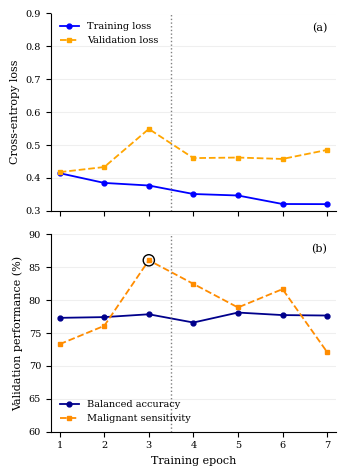

Figure 1 successfully generated.
PDF: /content/drive/MyDrive/ENGG680/Final_Report_Figures/Fig1_Model_Training_Selection.pdf
PNG: /content/drive/MyDrive/ENGG680/Final_Report_Figures/Fig1_Model_Training_Selection.png


In [15]:
# FIGURE 1 — Training History and Model Selection

import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# 1. Load saved training history
folder_path = "/content/drive/MyDrive/ENGG680"

history_path = os.path.join(
    folder_path,
    "Additional_Finetuning",
    "additional_finetuning_history.csv"
)

history = pd.read_csv(history_path)

# 2. Create output folder
output_dir = os.path.join(
    folder_path,
    "Final_Report_Figures"
)
os.makedirs(output_dir, exist_ok=True)

# 3. IEEE formatting
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

# 4. Create two-panel figure
fig, axes = plt.subplots(
    2, 1,
    figsize=(3.5, 4.8),
    sharex=True
)

epochs = history["epoch"]

# Panel (a): Training and validation loss
ax = axes[0]

ax.plot(
    epochs,
    history["train_loss"],
    "o-",
    color="blue",
    linewidth=1.3,
    markersize=3.5,
    label="Training loss"
)

ax.plot(
    epochs,
    history["val_loss"],
    "s--",
    color="orange",
    linewidth=1.3,
    markersize=3.5,
    label="Validation loss"
)

# Boundary between original training and further fine-tuning
ax.axvline(
    3.5,
    color="gray",
    linestyle=":",
    linewidth=1
)

ax.set_ylabel("Cross-entropy loss")
ax.set_xlim(0.8, 7.2)
ax.set_ylim(.30, .90)
ax.legend(loc="upper left", frameon=False)
ax.grid(axis="y", alpha=0.2)

ax.text(
    0.97, 0.95, "(a)",
    transform=ax.transAxes,
    ha="right",
    va="top"
)

# Panel (b): Validation performance

ax = axes[1]

ax.plot(
    epochs,
    history["val_balanced_accuracy"] * 100,
    "o-",
    color="darkblue",
    linewidth=1.3,
    markersize=3.5,
    label="Balanced accuracy"
)

ax.plot(
    epochs,
    history["val_malignant_recall"] * 100,
    "s--",
    color="darkorange",
    linewidth=1.3,
    markersize=3.5,
    label="Malignant sensitivity"
)

ax.axvline(
    3.5,
    color="grey",
    linestyle=":",
    linewidth=1
)

# Highlight selected original model (epoch 3)
selected = history.loc[history["epoch"] == 3].iloc[0]

ax.scatter(
    3,
    selected["val_malignant_recall"] * 100,
    s=65,
    facecolors="none",
    edgecolors="black",
    linewidths=1,
    zorder=5
)

ax.set_xlabel("Training epoch")
ax.set_ylabel("Validation performance (%)")
ax.set_xticks(range(1, 8))
ax.set_ylim(60, 90)
ax.yaxis.set_major_locator(MultipleLocator(5))

ax.legend(loc="lower left", frameon=False)
ax.grid(axis="y", alpha=0.2)

ax.text(
    0.97, 0.95, "(b)",
    transform=ax.transAxes,
    ha="right",
    va="top"
)

# 5. Final formatting
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.tight_layout(h_pad=1.3)

# 6. Save as vector PDF and high-resolution PNG
pdf_path = os.path.join(
    output_dir,
    "Fig1_Model_Training_Selection.pdf"
)

png_path = os.path.join(
    output_dir,
    "Fig1_Model_Training_Selection.png"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Figure 1 successfully generated.")
print("PDF:", pdf_path)
print("PNG:", png_path)


In [ ]:
# IEEE TABLE — CALIBRATION AND REFERRAL RESULTS
# Independent test set (n = 1,415)

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.stats.proportion import proportion_confint

# 1. Required variables from earlier notebook cells
required = [
    "test_true_labels",
    "test_uncalibrated_probs",
    "test_calibrated_probs",
    "test_before_ece",
    "test_after_ece",
    "test_before_brier",
    "test_after_brier",
    "test_before_nll",
    "test_after_nll"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Run the final test evaluation and calibration cells first. "
        "Missing variables: " + ", ".join(missing)
    )

y_true = np.asarray(test_true_labels)
threshold = 0.80

# 2. Calculate referral outcomes consistently
def referral_metrics(probabilities, labels, threshold=0.80):

    probabilities = np.asarray(probabilities)
    predictions = np.argmax(probabilities, axis=1)
    confidence = np.max(probabilities, axis=1)

    # Accept only confident benign predictions
    accepted = (
        (predictions == 0) &
        (confidence >= threshold)
    )
    referred = ~accepted

    malignant = labels == 1
    benign = labels == 0

    n = len(labels)
    n_referred = int(referred.sum())
    n_malignant = int(malignant.sum())

    referral_ci = proportion_confint(
        n_referred, n,
        alpha=0.05, method="wilson"
    )

    return {
        "accepted": int(accepted.sum()),
        "referred": n_referred,
        "referral_rate": 100 * n_referred / n,
        "referral_ci": tuple(100 * v for v in referral_ci),
        "benign_accepted": int((benign & accepted).sum()),
        "benign_referred": int((benign & referred).sum()),
        "malignant_referred": int((malignant & referred).sum()),
        "malignant_missed": int((malignant & accepted).sum()),
        "malignant_sensitivity": (
            100 * (malignant & referred).sum() / n_malignant
            if n_malignant else np.nan
        )
    }

before = referral_metrics(
    test_uncalibrated_probs, y_true, threshold
)

after = referral_metrics(
    test_calibrated_probs, y_true, threshold
)

# 3. Construct combined results table
def percent(value):
    return f"{value:.2f}%"

def count(value):
    return f"{value:,}"

def rate_with_ci(result):
    low, high = result["referral_ci"]
    return (
        f'{result["referral_rate"]:.2f}% '
        f'[{low:.2f}, {high:.2f}]'
    )

rows = [
    ["CALIBRATION", "", ""],
    ["Expected calibration error",
     f"{test_before_ece:.4f}",
     f"{test_after_ece:.4f}"],
    ["Brier score",
     f"{test_before_brier:.4f}",
     f"{test_after_brier:.4f}"],
    ["Negative log-likelihood",
     f"{test_before_nll:.4f}",
     f"{test_after_nll:.4f}"],

    ["REFERRAL (threshold = 0.80)", "", ""],
    ["Referred images",
     count(before["referred"]),
     count(after["referred"])],
    ["Referral rate (95% CI)",
     rate_with_ci(before),
     rate_with_ci(after)],
    ["Automatically accepted",
     count(before["accepted"]),
     count(after["accepted"])],
    ["Benign images accepted",
     count(before["benign_accepted"]),
     count(after["benign_accepted"])],
    ["Malignant images accepted",
     count(before["malignant_missed"]),
     count(after["malignant_missed"])],
    ["Malignant referral sensitivity",
     percent(before["malignant_sensitivity"]),
     percent(after["malignant_sensitivity"])]
]

columns = [
    "Metric",
    "Before calibration",
    "After calibration"
]

results_table = pd.DataFrame(rows, columns=columns)

display(results_table)

# ------------------------------------------------------------
# 4. Export as CSV
# ------------------------------------------------------------
folder_path = "/content/drive/MyDrive/ENGG680"
output_dir = os.path.join(folder_path, "Final_Report_Figures")
os.makedirs(output_dir, exist_ok=True)

results_table.to_csv(
    os.path.join(
        output_dir,
        "Table_Calibration_Referral.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 5. Render IEEE-style table
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig, ax = plt.subplots(figsize=(7.16, 3.1))
ax.axis("off")

table = ax.table(
    cellText=results_table.values,
    colLabels=results_table.columns,
    colWidths=[0.46, 0.27, 0.27],
    cellLoc="center",
    colLoc="center",
    loc="center",
    bbox=[0, 0.07, 1, 0.88]
)

table.auto_set_font_size(False)
table.set_fontsize(8)

nrows = len(results_table) + 1

# Remove all borders first
for (r, c), cell in table.get_celld().items():
    cell.set_facecolor("white")
    cell.set_edgecolor("black")
    cell.set_linewidth(0)
    cell.visible_edges = ""

    if c == 0:
        cell.get_text().set_ha("left")

# Header: top and bottom horizontal rules
for c in range(3):
    cell = table[(0, c)]
    cell.get_text().set_weight("bold")
    cell.visible_edges = "TB"
    cell.set_linewidth(0.8)

# Section headings and separator rules
for row_index in [1, 5]:
    for c in range(3):
        cell = table[(row_index, c)]
        cell.visible_edges = "T"
        cell.set_linewidth(0.6)
        cell.get_text().set_weight("bold")

# Bottom horizontal rule
for c in range(3):
    cell = table[(nrows - 1, c)]
    cell.visible_edges = "B"
    cell.set_linewidth(0.8)

ax.text(
    0.5, 0.99,
    "TABLE IV",
    ha="center", va="top",
    fontsize=8, fontweight="bold",
    transform=ax.transAxes
)

ax.text(
    0.5, 0.945,
    "CALIBRATION AND REFERRAL PERFORMANCE",
    ha="center", va="top",
    fontsize=8,
    transform=ax.transAxes
)

pdf_path = os.path.join(
    output_dir,
    "Table_Calibration_Referral.pdf"
)

png_path = os.path.join(
    output_dir,
    "Table_Calibration_Referral.png"
)

fig.savefig(pdf_path, bbox_inches="tight")
fig.savefig(png_path, dpi=600, bbox_inches="tight")

plt.show()

print("Saved PDF:", pdf_path)
print("Saved PNG:", png_path)
print(
    "Referral rate change:",
    f'{after["referral_rate"] - before["referral_rate"]:+.2f}',
    "percentage points"
)


RuntimeError: Run the final test evaluation and calibration cells first. Missing variables: test_true_labels, test_uncalibrated_probs, test_calibrated_probs, test_before_ece, test_after_ece, test_before_brier, test_after_brier, test_before_nll, test_after_nll

In [ ]:
# Step 16.51: Create and save final test confusion matrix

import os
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix from test predictions
cm = confusion_matrix(
    test_true_labels,
    test_predictions,
    labels=[0, 1]
)

# Create figure
fig, ax = plt.subplots(figsize=(7, 6))

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

cm_display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Augmented ResNet-18: Test Confusion Matrix",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Predicted Classification", fontsize=12)
ax.set_ylabel("True Classification", fontsize=12)

plt.tight_layout()

# Save high-resolution image
figure_path = os.path.join(
    results_folder,
    "augmented_resnet18_confusion_matrix.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nConfusion matrix:")
print(cm)

print("\nFigure saved to:")
print(figure_path)

NameError: name 'test_true_labels' is not defined

In [ ]:
# Step 16.52: Create and save final test ROC curve

import os
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    test_true_labels,
    test_malignant_probs
)

# Calculate ROC-AUC
roc_auc = roc_auc_score(
    test_true_labels,
    test_malignant_probs
)

# Create figure
fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    fpr,
    tpr,
    linewidth=2.5,
    label=f"Augmented ResNet-18 (AUC = {roc_auc:.4f})"
)

# Random classification reference line
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier (AUC = 0.50)"
)

ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate (Malignant Recall)", fontsize=12)

ax.set_title(
    "Augmented ResNet-18: Test ROC Curve",
    fontsize=14,
    pad=15
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()

# Save high-resolution figure
figure_path = os.path.join(
    results_folder,
    "augmented_resnet18_roc_curve.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"\nFinal test ROC-AUC: {roc_auc:.4f}")
print("\nFigure saved to:")
print(figure_path)

In [ ]:
# Step 16.53: Create and save test calibration plot

import os
import numpy as np
import matplotlib.pyplot as plt

# Calculate confidence and correctness for each prediction
def get_reliability_data(probabilities, true_labels, n_bins=10):

    confidence = np.max(probabilities, axis=1)
    predictions = np.argmax(probabilities, axis=1)
    correct = (predictions == true_labels).astype(float)

    bin_edges = np.linspace(0, 1, n_bins + 1)

    mean_confidence = []
    observed_accuracy = []
    bin_counts = []

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence <= bin_edges[i + 1])
            )
        else:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence < bin_edges[i + 1])
            )

        if np.sum(mask) > 0:
            mean_confidence.append(np.mean(confidence[mask]))
            observed_accuracy.append(np.mean(correct[mask]))
            bin_counts.append(np.sum(mask))

    return (
        np.array(mean_confidence),
        np.array(observed_accuracy),
        np.array(bin_counts)
    )


# Before temperature scaling
before_conf, before_acc, before_counts = get_reliability_data(
    test_uncalibrated_probs,
    test_true_labels
)

# After temperature scaling
after_conf, after_acc, after_counts = get_reliability_data(
    test_calibrated_probs,
    test_true_labels
)

# Create calibration figure
fig, ax = plt.subplots(figsize=(7, 6))

# Perfect calibration reference
ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

# Uncalibrated reliability
ax.plot(
    before_conf,
    before_acc,
    marker="o",
    linewidth=2,
    label=f"Before calibration (ECE = {test_before_ece:.4f})"
)

# Calibrated reliability
ax.plot(
    after_conf,
    after_acc,
    marker="s",
    linewidth=2,
    label=f"After calibration (ECE = {test_after_ece:.4f})"
)

ax.set_title(
    "Augmented ResNet-18: Test Calibration",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Mean Predicted Confidence", fontsize=12)
ax.set_ylabel("Observed Classification Accuracy", fontsize=12)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.grid(alpha=0.3)
ax.legend(loc="upper left")

plt.tight_layout()

# Save figure
calibration_figure_path = os.path.join(
    results_folder,
    "augmented_resnet18_calibration_plot.png"
)

plt.savefig(
    calibration_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("--- FINAL TEST CALIBRATION ---")
print(f"ECE before: {test_before_ece:.4f}")
print(f"ECE after:  {test_after_ece:.4f}")

print("\nFigure saved to:")
print(calibration_figure_path)

In [ ]:
# Step 16.54: Create final referral strategy visualization

import os
import numpy as np
import matplotlib.pyplot as plt

# Outcomes from independent test evaluation
categories = ["Benign", "Malignant"]

accepted_counts = [414, 0]
referred_counts = [765, 236]

x = np.arange(len(categories))

fig, ax = plt.subplots(figsize=(8, 6))

# Automatically accepted images
ax.bar(
    x,
    accepted_counts,
    label="Automatically Accepted as Benign",
    color="#4C9F70"
)

# Images referred for expert review
ax.bar(
    x,
    referred_counts,
    bottom=accepted_counts,
    label="Referred for Expert Review",
    color="#E69F00"
)

# Label each bar segment
for i in range(len(categories)):

    if accepted_counts[i] > 0:
        ax.text(
            x[i],
            accepted_counts[i] / 2,
            str(accepted_counts[i]),
            ha="center",
            va="center",
            fontsize=13
        )

    if referred_counts[i] > 0:
        ax.text(
            x[i],
            accepted_counts[i] + referred_counts[i] / 2,
            str(referred_counts[i]),
            ha="center",
            va="center",
            fontsize=13
        )

ax.set_xticks(x)
ax.set_xticklabels(categories)

ax.set_ylabel("Number of Test Images", fontsize=12)

ax.set_title(
    "Augmented ResNet-18: Confidence-Based Referral Outcomes",
    fontsize=13,
    pad=15
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

# Save figure
referral_figure_path = os.path.join(
    results_folder,
    "augmented_resnet18_referral_outcomes.png"
)

plt.savefig(
    referral_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("--- FINAL REFERRAL RESULTS ---")
print("Malignant images referred:", 236)
print("Malignant images automatically accepted:", 0)
print("Overall referral rate: 70.74%")

print("\nFigure saved to:")
print(referral_figure_path)

In [ ]:
# Step 16.55: Create final performance summary table

import os
import pandas as pd

# Load our saved bootstrap confidence intervals
ci_path = os.path.join(
    results_folder,
    "augmented_resnet18_bootstrap_95CI.csv"
)

ci_df = pd.read_csv(ci_path)

# Helper function to retrieve bootstrap confidence intervals
def get_ci(metric, percentage=False):
    row = ci_df.loc[ci_df["Metric"] == metric].iloc[0]

    lower = row["95% CI Lower"]
    upper = row["95% CI Upper"]

    if percentage:
        return f"{lower*100:.2f}%–{upper*100:.2f}%"

    return f"{lower:.4f}–{upper:.4f}"


# Create the final table
final_table = pd.DataFrame([
    ["Classification", "Accuracy",
     "73.99%", get_ci("Accuracy", True)],

    ["Classification", "Balanced Accuracy",
     "80.83%", get_ci("Balanced Accuracy", True)],

    ["Classification", "Malignant Recall",
     "91.10%", get_ci("Malignant Recall", True)],

    ["Classification", "Malignant Precision",
     "38.26%", get_ci("Malignant Precision", True)],

    ["Classification", "F1 Score",
     "0.5388", get_ci("F1 Score")],

    ["Classification", "ROC-AUC",
     "0.8981", get_ci("ROC-AUC")],

    ["Calibration", "ECE (After Calibration)",
     f"{test_after_ece:.4f}", "Not calculated"],

    ["Calibration", "Brier Score (After Calibration)",
     f"{test_after_brier:.4f}", "Not calculated"],

    ["Calibration", "NLL (After Calibration)",
     f"{test_after_nll:.4f}", "Not calculated"],

    ["Referral", "Referral Rate",
     f"{referral_rate*100:.2f}%",
     get_ci("Referral Rate", True)],

    ["Referral", "Malignant Referral Sensitivity",
     f"{malignant_referral_sensitivity*100:.2f}%",
     f"{lesion_ci_lower*100:.2f}%–{lesion_ci_upper*100:.2f}%"]
], columns=[
    "Category",
    "Metric",
    "Final Test Result",
    "95% Confidence Interval"
])

# Display table
print("--- FINAL ENGG 680 PERFORMANCE SUMMARY ---")
from IPython.display import display as notebook_display
notebook_display(final_table)

# Save as CSV
table_path = os.path.join(
    results_folder,
    "augmented_resnet18_final_performance_table.csv"
)

final_table.to_csv(table_path, index=False)

print("\nTable saved to:")
print(table_path)

print("\nFinal performance table complete!")

In [4]:
# Step 16.56 Compute statistical significance of Calibration
# We used a paired lesion level boot strap rather than paired t tests as ECE is a dataset level metric and paired t test cannot be performed on this type of data.


from google.colab import drive
drive.mount("/content/drive")

import os
import json
import numpy as np
import pandas as pd
from scipy.special import expit, logit

# ------------------------------------------------------------
# 1. Load saved results
# ------------------------------------------------------------
results_folder = "/content/drive/MyDrive/ENGG680/Final_Test_Results"
output_folder = "/content/drive/MyDrive/ENGG680/Final_Report_Figures"
os.makedirs(output_folder, exist_ok=True)

df = pd.read_csv(os.path.join(
    results_folder,
    "augmented_resnet18_test_predictions.csv"
))

with open(os.path.join(
    results_folder,
    "augmented_resnet18_final_summary.json"
), "r") as f:
    summary = json.load(f)

required = ["lesion_id", "true_label", "malignant_probability"]
assert all(c in df.columns for c in required)

y = df["true_label"].to_numpy(dtype=int)
lesion_ids = df["lesion_id"].to_numpy()

# Saved probabilities are AFTER temperature scaling
p_cal = df["malignant_probability"].to_numpy(dtype=float)
T = float(summary["temperature"])

assert np.isfinite(p_cal).all()
assert np.all((p_cal >= 0) & (p_cal <= 1))
assert set(np.unique(y)).issubset({0, 1})
assert T > 0

# Reverse temperature scaling to recover original probabilities
p_cal = np.clip(p_cal, 1e-12, 1 - 1e-12)
p_uncal = expit(T * logit(p_cal))

print("Images:", len(df))
print("Unique lesions:", df["lesion_id"].nunique())
print("Temperature:", T)

# ------------------------------------------------------------
# 2. Define calibration metrics
# ------------------------------------------------------------
def calibration_metrics(labels, p, n_bins=10):
    p = np.clip(np.asarray(p), 1e-12, 1 - 1e-12)
    labels = np.asarray(labels)

    # Binary Brier score
    brier = np.mean((p - labels) ** 2)

    # Binary negative log-likelihood
    nll = -np.mean(
        labels * np.log(p) +
        (1 - labels) * np.log1p(-p)
    )

    # Match the notebook's confidence-based ECE
    confidence = np.maximum(p, 1 - p)
    predictions = (p > 0.5).astype(int)
    correct = (predictions == labels).astype(float)

    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for b in range(n_bins):
        if b == n_bins - 1:
            mask = (confidence >= edges[b]) & (
                confidence <= edges[b + 1]
            )
        else:
            mask = (confidence >= edges[b]) & (
                confidence < edges[b + 1]
            )

        if mask.any():
            ece += mask.mean() * abs(
                correct[mask].mean() -
                confidence[mask].mean()
            )

    return np.array([ece, nll, brier])


metric_names = ["ECE", "NLL", "Brier score"]

before = calibration_metrics(y, p_uncal)
after = calibration_metrics(y, p_cal)

# Negative = improvement
observed_delta = after - before

print("\nObserved test results:")
for name, b, a, d in zip(
    metric_names, before, after, observed_delta
):
    print(f"{name:12s}: {b:.4f} -> {a:.4f}  delta={d:+.4f}")

# ------------------------------------------------------------
# 3. Prepare lesion-level groups
# ------------------------------------------------------------
rng = np.random.default_rng(42)

unique_lesions, group_idx = np.unique(
    lesion_ids, return_inverse=True
)

n_lesions = len(unique_lesions)

groups = [
    np.flatnonzero(group_idx == i)
    for i in range(n_lesions)
]

# ------------------------------------------------------------
# 4. Paired lesion-level bootstrap (2000 repetitions)
# ------------------------------------------------------------
N_BOOT = 2000
boot_deltas = np.empty((N_BOOT, 3))

for b in range(N_BOOT):
    sampled_groups = rng.integers(
        0, n_lesions, size=n_lesions
    )

    indices = np.concatenate([
        groups[g] for g in sampled_groups
    ])

    boot_deltas[b] = (
        calibration_metrics(y[indices], p_cal[indices])
        - calibration_metrics(y[indices], p_uncal[indices])
    )

ci_low = np.percentile(boot_deltas, 2.5, axis=0)
ci_high = np.percentile(boot_deltas, 97.5, axis=0)

# ------------------------------------------------------------
# 5. Paired lesion-level permutation tests
# ------------------------------------------------------------
# Null hypothesis: calibrated and uncalibrated predictions
# are exchangeable within lesions.
#
# Swap the two probability sets together for every image
# belonging to each randomly selected lesion.

N_PERM = 5000
perm_deltas = np.empty((N_PERM, 3))

for b in range(N_PERM):
    swap_by_lesion = rng.integers(
        0, 2, size=n_lesions
    ).astype(bool)

    swap = swap_by_lesion[group_idx]

    perm_before = np.where(swap, p_cal, p_uncal)
    perm_after = np.where(swap, p_uncal, p_cal)

    perm_deltas[b] = (
        calibration_metrics(y, perm_after)
        - calibration_metrics(y, perm_before)
    )

# Two-sided permutation p-values with +1 correction
p_values = (
    1 + np.sum(
        np.abs(perm_deltas) >= np.abs(observed_delta),
        axis=0
    )
) / (N_PERM + 1)

# ------------------------------------------------------------
# 6. Create results table
# ------------------------------------------------------------
results = pd.DataFrame({
    "Metric": metric_names,
    "Uncalibrated": before,
    "Calibrated": after,
    "Difference (after - before)": observed_delta,
    "95% CI lower": ci_low,
    "95% CI upper": ci_high,
    "Permutation p-value": p_values
})

results["95% CI"] = [
    f"[{lo:+.4f}, {hi:+.4f}]"
    for lo, hi in zip(ci_low, ci_high)
]

results["p-value"] = [
    f"{p:.4f}" for p in p_values
]

results["Significant (p < 0.05)"] = (
    p_values < 0.05
)

display(results[[
    "Metric",
    "Uncalibrated",
    "Calibrated",
    "Difference (after - before)",
    "95% CI",
    "p-value",
    "Significant (p < 0.05)"
]].round(4))

# ------------------------------------------------------------
# 7. Verify against original saved calibration summary
# ------------------------------------------------------------
saved_after = summary["calibration"]

print("\nComparison with saved calibrated metrics:")
for name, key, calculated in [
    ("ECE", "ece", after[0]),
    ("NLL", "nll", after[1]),
    ("Brier", "brier_score", after[2])
]:
    saved = float(saved_after[key])
    print(
        f"{name}: calculated={calculated:.6f}, "
        f"saved={saved:.6f}, "
        f"absolute difference={abs(calculated-saved):.6g}"
    )

# Fail if reconstructed metrics do not match saved results
assert np.allclose(
    after,
    [
        saved_after["ece"],
        saved_after["nll"],
        saved_after["brier_score"]
    ],
    atol=1e-4
), "Metrics do not match saved summary. Check probability columns."

# 8. Save results
csv_path = os.path.join(
    output_folder,
    "calibration_statistical_significance.csv"
)

results.to_csv(csv_path, index=False)

print("\nSaved results to:", csv_path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Images: 1415
Unique lesions: 1087
Temperature: 1.6472741540516778

Observed test results:
ECE         : 0.0793 -> 0.0281  delta=-0.0512
NLL         : 0.5223 -> 0.4976  delta=-0.0246
Brier score : 0.1717 -> 0.1656  delta=-0.0061


,Metric,Uncalibrated,Calibrated,Difference (after - before),95% CI,p-value,Significant (p < 0.05)
0,ECE,0.0793,0.0281,-0.0512,"[-0.0697, -0.0189]",0.0002,True
1,NLL,0.5223,0.4976,-0.0246,"[-0.0429, -0.0068]",0.0080,True
2,Brier score,0.1717,0.1656,-0.0061,"[-0.0101, -0.0020]",0.0026,True



Comparison with saved calibrated metrics:
ECE: calculated=0.028119, saved=0.028119, absolute difference=1.019e-08
NLL: calculated=0.497639, saved=0.497639, absolute difference=1.17342e-09
Brier: calculated=0.165562, saved=0.165562, absolute difference=1.36593e-10

Saved results to: /content/drive/MyDrive/ENGG680/Final_Report_Figures/calibration_statistical_significance.csv


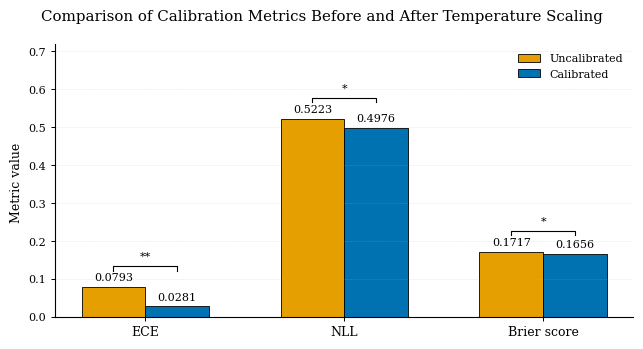

Saved PNG: /content/drive/MyDrive/ENGG680/Final_Report_Figures/calibration_significance_grouped.png
Saved PDF: /content/drive/MyDrive/ENGG680/Final_Report_Figures/calibration_significance_grouped.pdf


In [9]:
# Generate figure with calibration metrics and statistical significance at a 95% confidence interval.

output_folder = (
    "/content/drive/MyDrive/ENGG680/Final_Report_Figures"
)

# Load previously saved statistical results
df = pd.read_csv(os.path.join(
    output_folder,
    "calibration_statistical_significance.csv"
))

metrics = ["ECE", "NLL", "Brier score"]
df = df.set_index("Metric").loc[metrics]

uncalibrated = df["Uncalibrated"].to_numpy(dtype=float)
calibrated = df["Calibrated"].to_numpy(dtype=float)
p_values = df["Permutation p-value"].to_numpy(dtype=float)

# Holm correction for three comparisons
from statsmodels.stats.multitest import multipletests

_, adjusted_p, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="holm"
)

# IEEE formatting
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig, ax = plt.subplots(figsize=(6.5, 3.5))
fig.suptitle("Comparison of Calibration Metrics Before and After Temperature Scaling")

x = np.arange(len(metrics))
width = 0.32

# Grouped bars
bars_uncal = ax.bar(
    x - width/2,
    uncalibrated,
    width,
    label="Uncalibrated",
    color="#E69F00",  # Orange
    edgecolor="black",
    linewidth=0.6
)

bars_cal = ax.bar(
    x + width/2,
    calibrated,
    width,
    label="Calibrated",
    color="#0072B2",  # Blue
    edgecolor="black",
    linewidth=0.6
)

# Value labels
for bars in [bars_uncal, bars_cal]:
    for bar in bars:
        height = bar.get_height()

        ax.annotate(
            f"{height:.4f}",
            xy=(
                bar.get_x() + bar.get_width()/2,
                height
            ),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8
        )

# Significance annotations
for i, p in enumerate(adjusted_p):

    ymax = max(uncalibrated[i], calibrated[i])
    bracket_y = ymax + 0.055
    bracket_h = 0.012

    ax.plot(
        [
            x[i] - width/2,
            x[i] - width/2,
            x[i] + width/2,
            x[i] + width/2
        ],
        [
            bracket_y - bracket_h,
            bracket_y,
            bracket_y,
            bracket_y - bracket_h
        ],
        color="black",
        linewidth=0.8
    )

    if p < 0.001:
        label = "**"
    elif p < 0.05:
        label = "*"
    else:
        label = " "

    ax.text(
        x[i],
        bracket_y + 0.012,
        label,
        ha="center",
        va="bottom",
        fontsize=8
    )

# Axis formatting
ax.set_xticks(x)
ax.set_xticklabels([
    "ECE",
    "NLL",
    "Brier score"
])

ax.set_ylabel("Metric value ")
ax.set_ylim(0, 0.72)

ax.legend(
    loc="upper right",
    frameon=False,
    fontsize=8
)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    direction="out",
    length=3,
    width=0.7
)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.4,
    alpha=0.3
)

plt.tight_layout()

# Save figures
png_path = os.path.join(
    output_folder,
    "calibration_significance_grouped.png"
)

pdf_path = os.path.join(
    output_folder,
    "calibration_significance_grouped.pdf"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("Saved PNG:", png_path)
print("Saved PDF:", pdf_path)
